# Banking Customer & Loan Analytics
## Exploratory Data Analysis (EDA)

### 1. Project Overview

### 2. Library Imports

### 3. Project Path & Cleaned Dataset Loading

### 4. Dataset Overview

### 5. Customer Demographics Analysis

### 6. Account Analysis

### 7. Transaction Behaviour Analysis

### 8. Loan Portfolio Analysis

### 9. Card Adoption Analysis

### 10. Regional Analysis

### 11. Customer Segmentation

### 12. Key Business Insights

### 13. EDA Conclusion

### Objective

Import the required Python libraries for data manipulation, statistical analysis, and data visualization.



In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')

%matplotlib inline

### 2.1 Project Path Setup


Set the project directory paths and locate the cleaned datasets for Exploratory Data Analysis.

In [2]:
from pathlib import Path

project_path = Path("..")
cleaned_path = project_path / "data" / "cleaned"

print("Project Path:", project_path.resolve())
print("Cleaned Data Path:", cleaned_path.resolve())
print("Cleaned Folder Exists:", cleaned_path.exists())

Project Path: C:\Users\sarfraj shaikh\Desktop\Banking Customer Behaviour, Transaction & Loan Portfolio Analysis
Cleaned Data Path: C:\Users\sarfraj shaikh\Desktop\Banking Customer Behaviour, Transaction & Loan Portfolio Analysis\Data\cleaned
Cleaned Folder Exists: True


### 2.2 Load Cleaned Datasets


Load all seven cleaned datasets into a dictionary for further analysis.

In [3]:
date_columns = {
    'Accounts': ['opened_date'],
    'Transactions': ['txn_date'],
    'Loans': ['loan_date'],
    'Cards': ['issued_date']
}

file_names = {
    'Customers': 'bank-customers.csv',
    'Accounts': 'bank-accounts.csv',
    'Account_Holders': 'bank-account-holders.csv',
    'Transactions': 'bank-transactions(1).csv',
    'Loans': 'bank-loans.csv',
    'Cards': 'bank-cards.csv',
    'Counties': 'bank-counties.csv'
}

datasets = {}

for name, filename in file_names.items():

    datasets[name] = pd.read_csv(
        cleaned_path / filename,
        parse_dates=date_columns.get(name, [])
    )

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [4]:
customers = datasets['Customers']
accounts = datasets['Accounts']
account_holders = datasets['Account_Holders']
transactions = datasets['Transactions']
loans = datasets['Loans']
cards = datasets['Cards']
counties = datasets['Counties']

### 2.4: Dataset Loading Verification

In [5]:
for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Customers: (1034, 5)
Accounts: (900, 5)
Account_Holders: (1034, 4)
Transactions: (102880, 8)
Loans: (296, 7)
Cards: (232, 4)
Counties: (15, 7)


## 4. Dataset Overview

Understand the overall structure, size, and memory usage of all seven cleaned datasets before performing exploratory data analysis.

In [6]:
dataset_overview = []

for name, df in datasets.items():

    dataset_overview.append({
        'Dataset': name,
        'Rows': df.shape[0],
        'Columns': df.shape[1],
        'Memory Usage (MB)': round(
            df.memory_usage(deep=True).sum() / (1024 ** 2), 3
        )
    })

dataset_overview = pd.DataFrame(dataset_overview)

dataset_overview

,Dataset,Rows,Columns,Memory Usage (MB)
0,Customers,1034,5,0.154
1,Accounts,900,5,0.131
2,Account_Holders,1034,4,0.085
3,Transactions,102880,8,20.982
4,Loans,296,7,0.032
5,Cards,232,4,0.019
6,Counties,15,7,0.003


### Observations & Interpretation

- The Transactions dataset is the largest dataset, containing 102,880 records and consuming approximately 20.982 MB of memory.
- The Customers and Account_Holders datasets both contain 1,034 records.
- The Counties dataset is the smallest, containing only 15 records.
- Across all seven datasets, there are 106,391 records and 40 columns.
- The overall dataset size is manageable for analysis using Pandas without requiring immediate memory optimization.

**Conclusion:** The dataset structure and size are suitable for further exploratory data analysis.

## 5. Dataset Structure & Column Overview



Examine the columns and their data types across all seven datasets to understand the information available for exploratory data analysis.

In [7]:
for name, df in datasets.items():

    print(f"\n{'=' * 60}")
    print(f"Dataset: {name}")
    print(f"{'=' * 60}")

    column_overview = pd.DataFrame({
        'Column Name': df.columns,
        'Data Type': df.dtypes.astype(str).values
    })

    display(column_overview)


Dataset: Customers


,Column Name,Data Type
0,customer_id,int64
1,full_name,object
2,gender,object
3,birth_year,int64
4,county_id,int64



Dataset: Accounts


,Column Name,Data Type
0,account_id,int64
1,county_id,int64
2,opened_date,datetime64[ns]
3,account_type,object
4,statement_frequency,object



Dataset: Account_Holders


,Column Name,Data Type
0,holder_id,int64
1,account_id,int64
2,customer_id,int64
3,holder_type,object


... (4 outputs left out)


Dataset: Cards


,Column Name,Data Type
0,card_id,int64
1,holder_id,int64
2,card_type,object
3,issued_date,datetime64[ns]



Dataset: Counties


,Column Name,Data Type
0,county_id,int64
1,county,object
2,region,object
3,population,int64
4,avg_monthly_income_kes,int64
5,unemployment_pct,float64
6,urban_pct,float64


### Observations

- The Customers dataset contains demographic and customer identification information.
- The Accounts dataset provides account-related information and account opening dates.
- The Account_Holders dataset establishes relationships between customers and accounts.
- The Transactions dataset contains transaction-level financial and behavioural information.
- The Loans dataset provides loan amounts, repayment schedules, durations, and loan statuses.
- The Cards dataset contains information about issued banking cards.
- The Counties dataset provides regional and demographic information.

### Analytical Relevance

The available columns support customer segmentation, transaction behaviour analysis, loan portfolio analysis, card adoption analysis, and regional comparisons.

The datasets will be analysed at their appropriate levels, such as customer-level, account-level, transaction-level, and county-level, while respecting the available relationships and data limitations.

## 5. Customer Demographics Analysis

### Objective

Analyse the demographic characteristics of bank customers using gender and estimated age.

### Business Questions

- What is the gender distribution of bank customers?
- How are customers distributed across different age groups?

### Business Relevance

Understanding customer demographics can help the bank identify customer segments and potential opportunities for targeted banking products.

In [8]:
customers['age'] = 2026 - customers['birth_year']

customers[['customer_id', 'birth_year', 'age']].head()

,customer_id,birth_year,age
0,10001,1973,53
1,10002,1982,44
2,10003,1993,33
3,10004,1978,48
4,10005,1990,36


In [9]:
customers['age'].describe()

count    1034.000000
mean       40.593810
std        10.409682
min        20.000000
25%        33.000000
50%        40.000000
75%        48.000000
max        73.000000
Name: age, dtype: float64

### Observations & Interpretation

- The dataset contains 1,034 customers.
- The average estimated customer age is approximately 41 years.
- The median customer age is 40 years.
- Approximately 50% of customers fall within the age range of 33 to 48 years.
- Customer ages range from 20 to 73 years.
- The standard deviation of 10.41 years indicates variation in the customer age distribution.

**Business Interpretation:** The bank serves customers across different age groups, with the central age distribution concentrated around 33–48 years. Further age-group analysis can help identify customer segments for banking product opportunities.

### Age Group Segmentation

Customers are categorized into different age groups to understand the age-wise distribution of the bank's customer base.

The following age groups will be used:

- 18–25: Young Adults
- 26–35: Early Career
- 36–45: Mid Career
- 46–55: Mature Customers
- 56+: Senior Customers

In [10]:
bins = [17, 25, 35, 45, 55, np.inf]

labels = [
    '18-25',
    '26-35',
    '36-45',
    '46-55',
    '56+'
]

customers['age_group'] = pd.cut(
    customers['age'],
    bins=bins,
    labels=labels
)

In [11]:
age_group_summary = (
    customers['age_group']
    .value_counts()
    .sort_index()
    .reset_index()
)

age_group_summary.columns = ['Age Group', 'Customers']

age_group_summary['Percentage'] = (
    age_group_summary['Customers'] /
    len(customers) * 100
).round(2)

age_group_summary

,Age Group,Customers,Percentage
0,18-25,83,8.03
1,26-35,263,25.44
2,36-45,345,33.37
3,46-55,260,25.15
4,56+,83,8.03


### Observations & Interpretation

- The 36–45 age group represents the largest customer segment, with 345 customers (33.37%).
- The 26–35 age group accounts for 263 customers (25.44%).
- The 46–55 age group represents 260 customers (25.15%).
- Both the 18–25 and 56+ age groups have 83 customers each (8.03%).
- Approximately 58.52% of customers belong to the 26–45 age range.

**Business Interpretation:** The bank's customer base is concentrated in the 26–45 age range. Younger and older customer segments represent comparatively smaller opportunities for further customer engagement and product adoption.

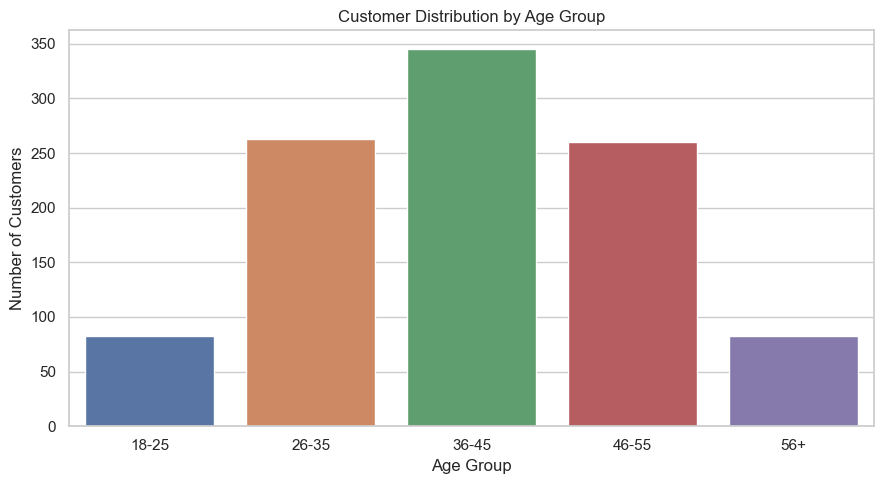

In [12]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=age_group_summary,
    x='Age Group',
    y='Customers'
)

plt.title('Customer Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

### Visualization Interpretation

The bar chart highlights that the 36–45 age group has the highest customer representation. The 26–35 and 46–55 age groups also contribute significantly to the customer base.

In contrast, the 18–25 and 56+ age groups have comparatively fewer customers.

**Business Insight:** The bank can explore targeted engagement strategies for younger and older customer segments while continuing to serve its largest customer segment effectively.

In [13]:
gender_summary = (
    customers['gender']
    .value_counts()
    .reset_index()
)

gender_summary.columns = ['Gender', 'Customers']

gender_summary['Percentage'] = (
    gender_summary['Customers'] /
    len(customers) * 100
).round(2)

gender_summary

,Gender,Customers,Percentage
0,Male,542,52.42
1,Female,492,47.58


### Observations & Interpretation

- Male customers account for 542 customers (52.42%).
- Female customers account for 492 customers (47.58%).
- The difference between male and female customers is 50.
- The customer base has a relatively balanced gender distribution.

**Business Interpretation:** The bank has a fairly balanced male and female customer base. Gender alone may not be sufficient for identifying product opportunities; it should be analysed alongside account types, card adoption, and transaction behaviour.

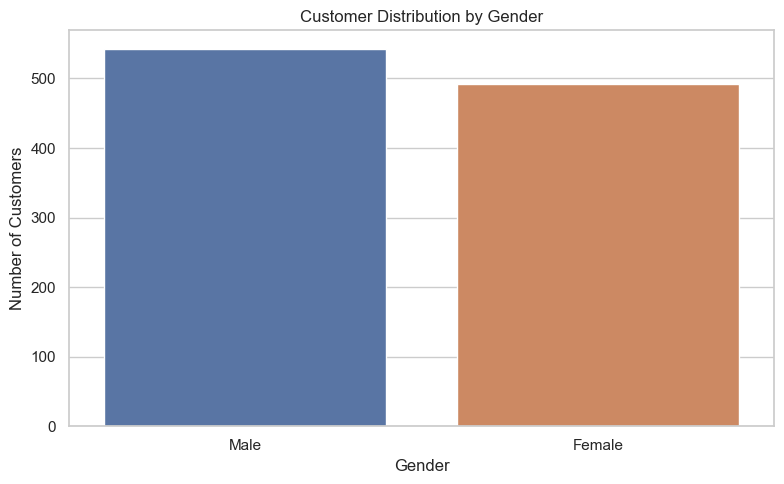

In [14]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=gender_summary,
    x='Gender',
    y='Customers'
)

plt.title('Customer Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

### Visualization Interpretation

The bar chart shows a relatively balanced distribution of male and female customers. Male customers have slightly higher representation than female customers, with a difference of 50 customers.

**Business Insight:** The bank serves a relatively balanced gender-based customer population. Further analysis of banking product adoption and transaction behaviour across gender groups may help identify meaningful business opportunities.

### Key Findings

**Age Analysis**

- The average estimated customer age is approximately 41 years.
- The 36–45 age group represents the largest segment, with 345 customers (33.37%).
- The 26–45 age range accounts for approximately 58.52% of customers.
- The 18–25 and 56+ age groups have the lowest representation, with 83 customers each (8.03%).

**Gender Analysis**

- Male customers represent 52.42% of the customer base.
- Female customers represent 47.58%.
- The difference between male and female customers is 50.

### Business Insights

- The bank's customer base is primarily concentrated in the 26–45 age range.
- Younger and older age groups have comparatively lower representation.
- The gender distribution is relatively balanced.
- Age and gender can be combined with banking product usage to identify potential customer segments.

### Conclusion

The demographic analysis provides an overview of the bank's customer population based on age and gender.

The findings indicate that customers aged 26–45 form the majority of the customer base, while male and female representation remains relatively balanced.

These demographic characteristics can support further analysis of account usage, card adoption, and customer transaction behaviour.

**Note:** Customer age is estimated using 2026 as the reference year because the exact date of birth is unavailable.

# 6. Account Analysis

### Objective

Analyse the bank's account portfolio to understand account type distribution and statement frequency preferences.

### Business Questions

- What types of accounts are maintained by customers?
- Which account types are most common?
- What is the distribution of statement frequency?

### Business Relevance

Understanding account distribution can help the bank identify customer preferences and explore opportunities for suitable banking products and services.

### 6.2 Account Type Distribution

In [15]:
account_type_summary = (
    accounts['account_type']
    .value_counts()
    .reset_index()
)

account_type_summary.columns = ['Account Type', 'Accounts']

account_type_summary['Percentage'] = (
    account_type_summary['Accounts'] /
    len(accounts) * 100
).round(2)

account_type_summary

,Account Type,Accounts,Percentage
0,Current,461,51.22
1,Savings,314,34.89
2,Business,125,13.89


### Observations & Interpretation

- Current accounts represent 461 accounts (51.22%), making them the largest account category.
- Savings accounts account for 314 accounts (34.89%).
- Business accounts represent 125 accounts (13.89%).
- Current accounts exceed savings accounts by 147 accounts.

**Business Interpretation:** Current accounts dominate the bank's account portfolio, while savings and business accounts have comparatively lower representation. The bank can further investigate opportunities to increase savings and business account adoption.

### 6.3 Account Type Visualization

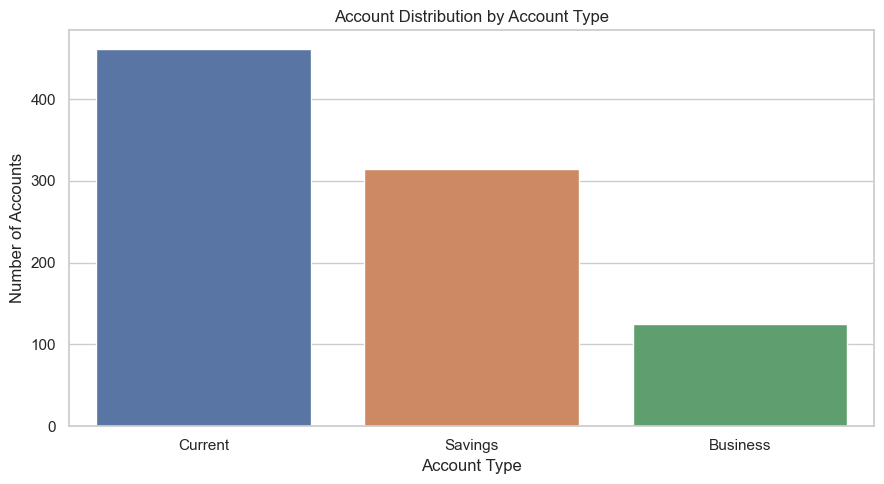

In [16]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=account_type_summary,
    x='Account Type',
    y='Accounts'
)

plt.title('Account Distribution by Account Type')
plt.xlabel('Account Type')
plt.ylabel('Number of Accounts')

plt.tight_layout()
plt.show()

### Visualization Interpretation

The bar chart shows that Current Accounts dominate the bank's account portfolio, followed by Savings Accounts.

Business Accounts have comparatively lower representation, indicating a smaller share of the overall account portfolio.

**Business Insight:** The bank can explore opportunities to increase savings and business account adoption through suitable product offerings and customer engagement strategies.

### 6.4 Statement Frequency Analysis

In [17]:
statement_frequency_summary = (
    accounts['statement_frequency']
    .value_counts()
    .reset_index()
)

statement_frequency_summary.columns = [
    'Statement Frequency',
    'Accounts'
]

statement_frequency_summary['Percentage'] = (
    statement_frequency_summary['Accounts'] /
    len(accounts) * 100
).round(2)

statement_frequency_summary

,Statement Frequency,Accounts,Percentage
0,Monthly,658,73.11
1,Weekly,153,17.00
2,Per transaction,89,9.89


### Observations & Interpretation

- Monthly statement frequency is the most common option, covering 658 accounts (73.11%).
- Weekly statements are used by 153 accounts (17.00%).
- Per-transaction statements account for 89 accounts (9.89%).
- The majority of accounts follow a monthly statement schedule.

**Business Interpretation:** Monthly statements dominate the bank's account portfolio. The bank can use this information to understand customer preferences and evaluate whether alternative statement delivery options could improve customer engagement.

### Statement Frequency Visualization

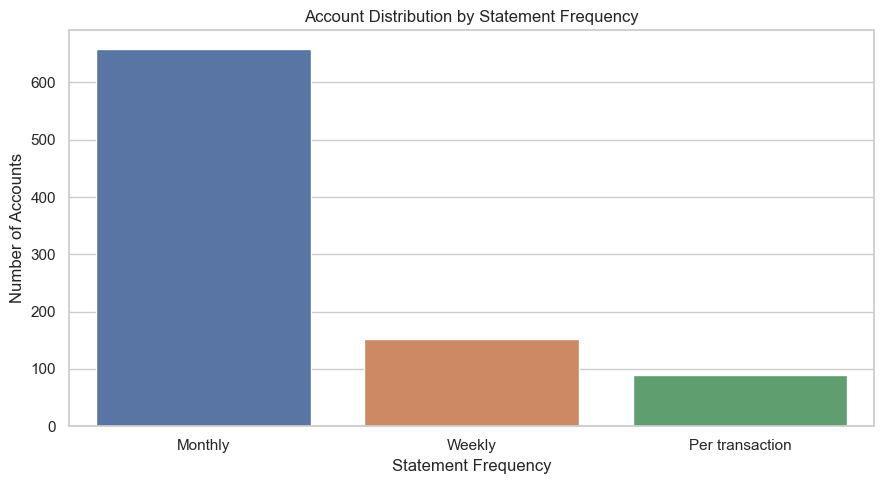

In [18]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=statement_frequency_summary,
    x='Statement Frequency',
    y='Accounts'
)

plt.title('Account Distribution by Statement Frequency')
plt.xlabel('Statement Frequency')
plt.ylabel('Number of Accounts')

plt.tight_layout()
plt.show()

### Visualization Interpretation

The bar chart shows a strong preference for monthly statements among bank accounts.

Monthly statements account for the majority of accounts, while weekly and per-transaction statements have comparatively lower representation.

**Business Insight:** The bank can use the observed statement frequency preferences to evaluate customer communication and statement delivery strategies.

### 6.5: Account Analysis – Key Findings & Conclusion

### Key Findings

**Account Type Analysis**

- Current accounts represent the largest category, with 461 accounts (51.22%).
- Savings accounts account for 314 accounts (34.89%).
- Business accounts account for 125 accounts (13.89%).

**Statement Frequency Analysis**

- Monthly statements are the most common, covering 658 accounts (73.11%).
- Weekly statements account for 153 accounts (17.00%).
- Per-transaction statements account for 89 accounts (9.89%).

### Business Insights

- Current accounts dominate the bank's account portfolio.
- Savings and business accounts have comparatively lower representation.
- Monthly statements are the preferred statement frequency in the dataset.
- Account type and statement frequency can help the bank understand its existing account portfolio.

### Conclusion

The account analysis shows that Current Accounts represent the largest share of the bank's account portfolio, while monthly statements are the most common statement frequency.

These findings provide an overview of account preferences and can support further analysis of customer banking behaviour and product adoption.

# 7. Transaction Behaviour Analysis


### Objective

Analyse transaction patterns to understand transaction volume, transaction values, transaction types, and customer banking behaviour.

### Business Questions

- How many transactions are recorded in the dataset?
- What is the total and average transaction value?
- How do transaction types and channels contribute to overall transaction activity?
- How do transaction frequency and value vary across accounts?

### Business Relevance

Understanding transaction behaviour can help the bank identify customer activity patterns, preferred transaction channels, and opportunities to improve banking services.

### 7.2 Overall Transaction Summary

In [19]:
transaction_summary = pd.DataFrame({
    'Metric': [
        'Total Transactions',
        'Total Transaction Value',
        'Average Transaction Value',
        'Median Transaction Value',
        'Minimum Transaction Value',
        'Maximum Transaction Value'
    ],
    'Value': [
        transactions['transaction_id'].count(),
        transactions['amount_kes'].sum(),
        transactions['amount_kes'].mean(),
        transactions['amount_kes'].median(),
        transactions['amount_kes'].min(),
        transactions['amount_kes'].max()
    ]
})

transaction_summary

,Metric,Value
0,Total Transactions,1.028800e+05
1,Total Transaction Value,4.951516e+09
2,Average Transaction Value,4.812905e+04
3,Median Transaction Value,3.562650e+04
4,Minimum Transaction Value,5.700000e+01
5,Maximum Transaction Value,3.372000e+06


In [20]:
transactions[['amount_kes', 'balance_kes']].describe()

,amount_kes,balance_kes
count,1.028800e+05,1.028800e+05
mean,4.812905e+04,4.771548e+05
std,5.509190e+04,5.869703e+05
min,5.700000e+01,4.000000e+01
25%,1.170000e+04,1.251718e+05
50%,3.562650e+04,2.906430e+05
75%,6.628600e+04,6.039500e+05
max,3.372000e+06,9.480312e+06


### Observations & Interpretation

- The dataset contains 102,880 transactions.
- The total transaction value is approximately KES 4.95 billion.
- The average transaction amount is KES 48,129.05, while the median is KES 35,626.50.
- Transaction amounts range from KES 57 to KES 3,372,000.
- The standard deviation of transaction amounts is approximately KES 55,091.90.
- The average account balance is KES 477,154.82, with a median of KES 290,643.

**Business Interpretation:**

The difference between the average and median transaction amounts suggests that some higher-value transactions may influence the overall average. The bank should consider both average and median values when understanding transaction behaviour.

Account balances represent post-transaction balances and should not be interpreted as bank profit or total bank funds.

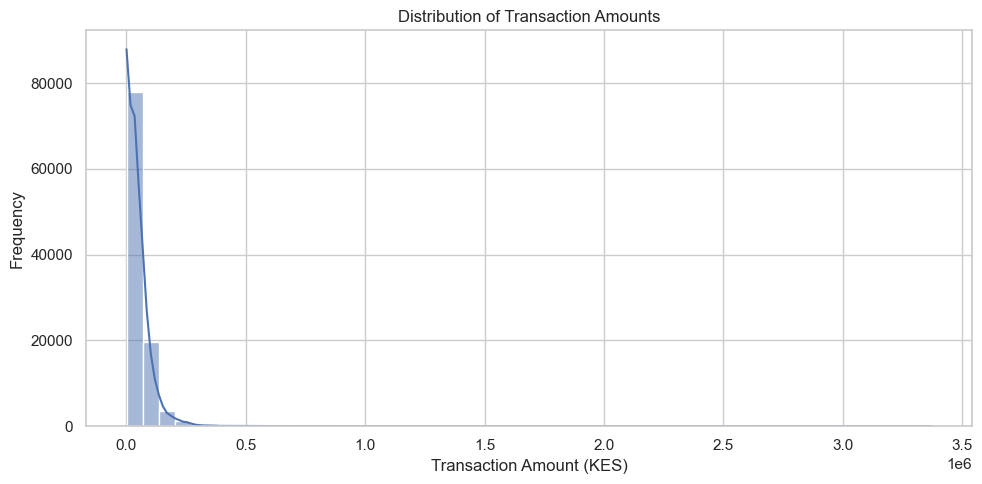

In [21]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=transactions,
    x='amount_kes',
    bins=50,
    kde=True
)

plt.title('Distribution of Transaction Amounts')
plt.xlabel('Transaction Amount (KES)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

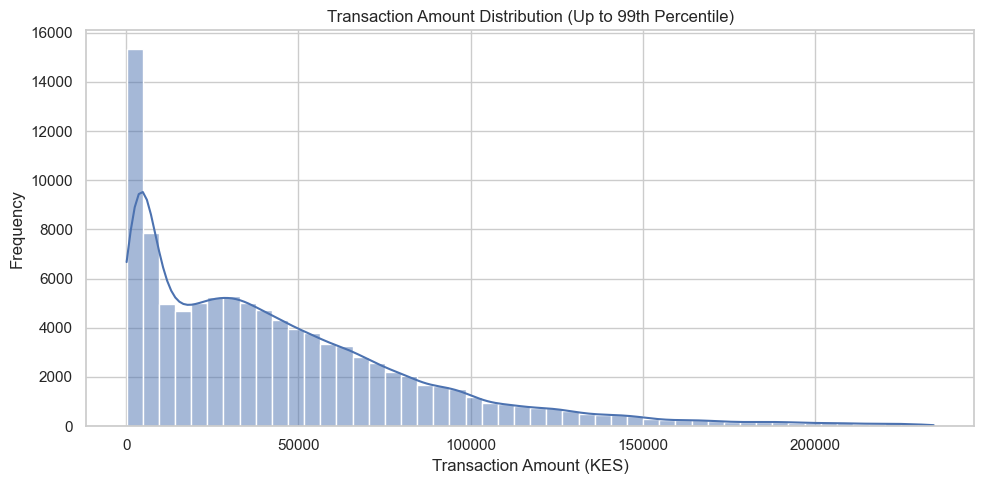

In [22]:
upper_limit = transactions['amount_kes'].quantile(0.99)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=transactions[transactions['amount_kes'] <= upper_limit],
    x='amount_kes',
    bins=50,
    kde=True
)

plt.title('Transaction Amount Distribution (Up to 99th Percentile)')
plt.xlabel('Transaction Amount (KES)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

**Key Observations:**

- Transaction amounts show a positively skewed distribution.
- Lower-value transactions occur more frequently than higher-value transactions.
- Transaction frequency generally decreases as transaction amounts increase.
- A small proportion of transactions have relatively high monetary values.
- The distribution remains right-skewed even when visualized up to the 99th percentile.

**Business Interpretation:**

The bank processes a large number of lower-value transactions, while high-value transactions occur less frequently. Understanding transaction value patterns can help the bank identify different transaction behaviour and customer banking needs.

### 7.3 Transaction Type Analysis

In [23]:
transaction_type_summary = (
    transactions['txn_type']
    .value_counts()
    .reset_index()
)

transaction_type_summary.columns = [
    'Transaction Type',
    'Transaction Count'
]

transaction_type_summary['Percentage'] = (
    transaction_type_summary['Transaction Count']
    / len(transactions) * 100
).round(2)

transaction_type_summary

,Transaction Type,Transaction Count,Percentage
0,DEBIT,60365,58.68
1,CREDIT,42515,41.32


### Key Observations

- DEBIT transactions account for 58.68% of total transactions.
- CREDIT transactions account for 41.32% of total transactions.
- DEBIT transactions exceed CREDIT transactions by 17,850.
- The transaction volume is higher on the debit side.

**Business Interpretation:**

The higher number of DEBIT transactions indicates greater debit-side transaction activity across bank accounts. Further analysis of transaction values is required to understand the monetary contribution of CREDIT and DEBIT transactions.

### 7.4 Transaction Value by Type

In [24]:
transaction_type_value = (
    transactions.groupby('txn_type')['amount_kes']
    .agg(['count', 'sum', 'mean', 'median'])
    .reset_index()
)

transaction_type_value.columns = [
    'Transaction Type',
    'Transaction Count',
    'Total Transaction Value',
    'Average Transaction Value',
    'Median Transaction Value'
]

transaction_type_value

,Transaction Type,Transaction Count,Total Transaction Value,Average Transaction Value,Median Transaction Value
0,CREDIT,42515,2819470406,66317.074115,52594.0
1,DEBIT,60365,2132046008,35319.241415,24400.0


**Key Observations:**

- DEBIT transactions account for 58.68% of total transaction volume, while CREDIT transactions account for 41.32%.
- Total CREDIT transaction value is approximately KES 2.82 billion.
- Total DEBIT transaction value is approximately KES 2.13 billion.
- Average CREDIT transaction value (KES 66,317.07) is higher than average DEBIT transaction value (KES 35,319.24).
- Median CREDIT transaction value is also higher than median DEBIT transaction value.

**Business Interpretation:**

DEBIT transactions occur more frequently, but CREDIT transactions have a higher total and average monetary value. This highlights the difference between transaction frequency and transaction value when analysing customer banking behaviour.

### 7.5 Transaction Channel Analysis

In [25]:
channel_summary = (
    transactions['channel']
    .value_counts()
    .reset_index()
)

channel_summary.columns = [
    'Channel',
    'Transaction Count'
]

channel_summary['Percentage'] = (
    channel_summary['Transaction Count']
    / len(transactions) * 100
).round(2)

channel_summary

,Channel,Transaction Count,Percentage
0,M-Pesa,40292,39.16
1,ATM cash withdrawal,15930,15.48
2,Standing order,15598,15.16
3,Bank transfer,15424,14.99
4,Branch,7668,7.45
5,Card POS,4274,4.15
6,Interest,3694,3.59


**Key Observations:**

- M-Pesa is the most frequently used channel, accounting for 39.16% of transactions.
- ATM cash withdrawals contribute 15.48% of total transactions.
- Standing orders and Bank transfers account for 15.16% and 14.99%, respectively.
- Branch transactions represent 7.45% of total volume.
- Card POS transactions account for only 4.15%.
- Interest transactions contribute 3.59%.

**Business Interpretation:**

M-Pesa represents the largest share of transaction activity in the dataset. ATM withdrawals, standing orders and bank transfers also contribute significantly. The relatively low Card POS share may indicate an opportunity to investigate card-based transaction adoption. However, transaction channel data alone cannot establish why customers use particular channels.

### 7.6 Transaction Value by Channel

In [26]:
channel_value_summary = (
    transactions.groupby('channel')['amount_kes']
    .agg(['count', 'sum', 'mean', 'median'])
    .reset_index()
)

channel_value_summary.columns = [
    'Channel',
    'Transaction Count',
    'Total Transaction Value',
    'Average Transaction Value',
    'Median Transaction Value'
]

channel_value_summary

,Channel,Transaction Count,Total Transaction Value,Average Transaction Value,Median Transaction Value
0,ATM cash withdrawal,15930,773290500,48543.032015,38400.0
1,Bank transfer,15424,1216222864,78852.623444,63716.0
2,Branch,7668,563910051,73540.695227,55845.5
3,Card POS,4274,13683530,3201.574637,2523.0
4,Interest,3694,31587160,8550.936654,5704.0
5,M-Pesa,40292,2219887290,55094.988832,43528.5
6,Standing order,15598,132935019,8522.568214,4528.0


**Key Observations:**

- M-Pesa contributes approximately KES 2.22 billion, the highest total transaction value.
- Bank Transfer contributes approximately KES 1.22 billion and has the highest average transaction value of KES 78,852.62.
- ATM cash withdrawals contribute approximately KES 773.29 million.
- Branch transactions have an average transaction value of KES 73,540.70.
- Standing Orders contribute approximately KES 132.94 million.
- Card POS has the lowest total and average transaction value.

**Business Interpretation:**

M-Pesa dominates transaction volume and total monetary value. Bank Transfer and Branch transactions have relatively high average transaction values, indicating differences in transaction behaviour across channels. These patterns can help identify channel-specific banking service opportunities.

### Visualize channel-wise transaction value

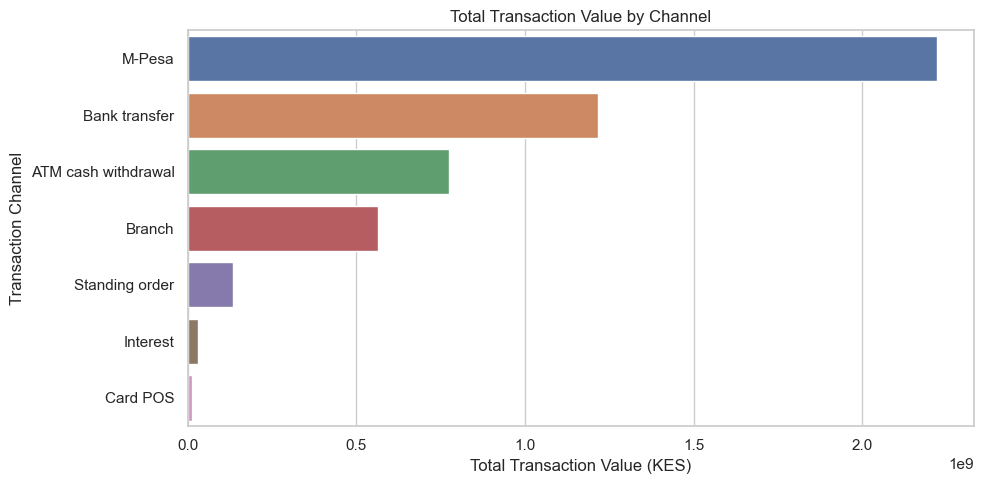

In [27]:
channel_plot = channel_value_summary.sort_values(
    'Total Transaction Value',
    ascending=False
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=channel_plot,
    x='Total Transaction Value',
    y='Channel'
)

plt.title('Total Transaction Value by Channel')
plt.xlabel('Total Transaction Value (KES)')
plt.ylabel('Transaction Channel')

plt.tight_layout()
plt.show()

**Chart Interpretation:**

- M-Pesa contributes the highest total transaction value among all channels.
- Bank Transfer ranks second, followed by ATM Cash Withdrawal and Branch.
- Standing Order, Interest and Card POS contribute comparatively lower transaction values.
- The chart highlights the difference in monetary contribution across transaction channels.

**Business Insight:**

M-Pesa is the leading channel in terms of overall transaction value, while Bank Transfer generates higher average transaction values per transaction. The bank can use these differences to understand channel-specific transaction behaviour and evaluate opportunities for service improvements.

### 7.7 Monthly Transaction Trend

In [28]:
transactions['txn_month'] = (
    transactions['txn_date'].dt.to_period('M')
)

monthly_transaction_summary = (
    transactions.groupby('txn_month')
    .agg(
        Transaction_Count=('transaction_id', 'count'),
        Total_Transaction_Value=('amount_kes', 'sum'),
        Average_Transaction_Value=('amount_kes', 'mean')
    )
    .reset_index()
)

monthly_transaction_summary['txn_month'] = (
    monthly_transaction_summary['txn_month'].astype(str)
)

monthly_transaction_summary

,txn_month,Transaction_Count,Total_Transaction_Value,Average_Transaction_Value
0,2021-01,149,10853828,72844.483221
1,2021-02,281,14754579,52507.398577
2,2021-03,453,22222000,49055.187638
3,2021-04,525,27917189,53175.598095
4,2021-05,664,34322118,51689.936747
5,2021-06,824,38490758,46712.084951
6,2021-07,823,43620381,53001.678007
7,2021-08,936,49440073,52820.590812
8,2021-09,1243,59036860,47495.462591
9,2021-10,1141,59041083,51745.033304


**Key Observations:**

- The analysis covers 48 months from January 2021 to December 2024.
- Monthly transaction count increased from 149 in January 2021 to 3,346 in December 2024.
- September 2024 recorded the highest monthly transaction count of 3,538.
- December 2024 recorded the highest monthly transaction value of approximately KES 164.18 million.
- Monthly transaction activity shows an overall upward trend with fluctuations.
- Average transaction value varies across months.

**Business Interpretation:**

The dataset shows an increase in monthly transaction activity over the analysis period. Higher transaction volume appears to contribute to higher monthly transaction values. Monitoring both metrics can help understand changes in banking transaction behaviour.

### Monthly Transaction Trend Visualization

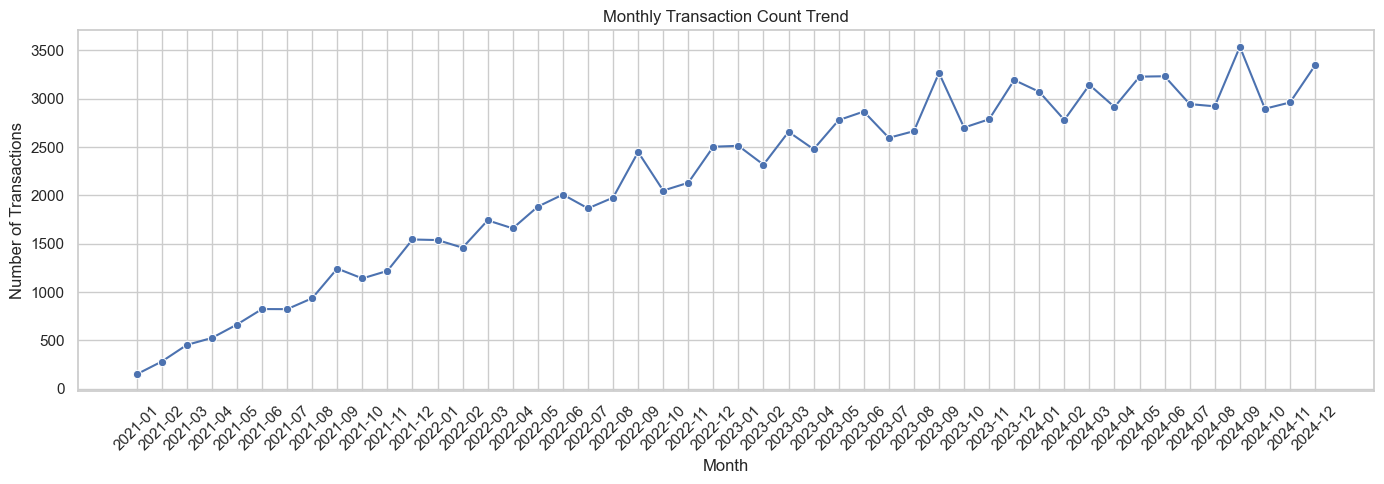

In [29]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_transaction_summary,
    x='txn_month',
    y='Transaction_Count',
    marker='o'
)

plt.title('Monthly Transaction Count Trend')
plt.xlabel('Month')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

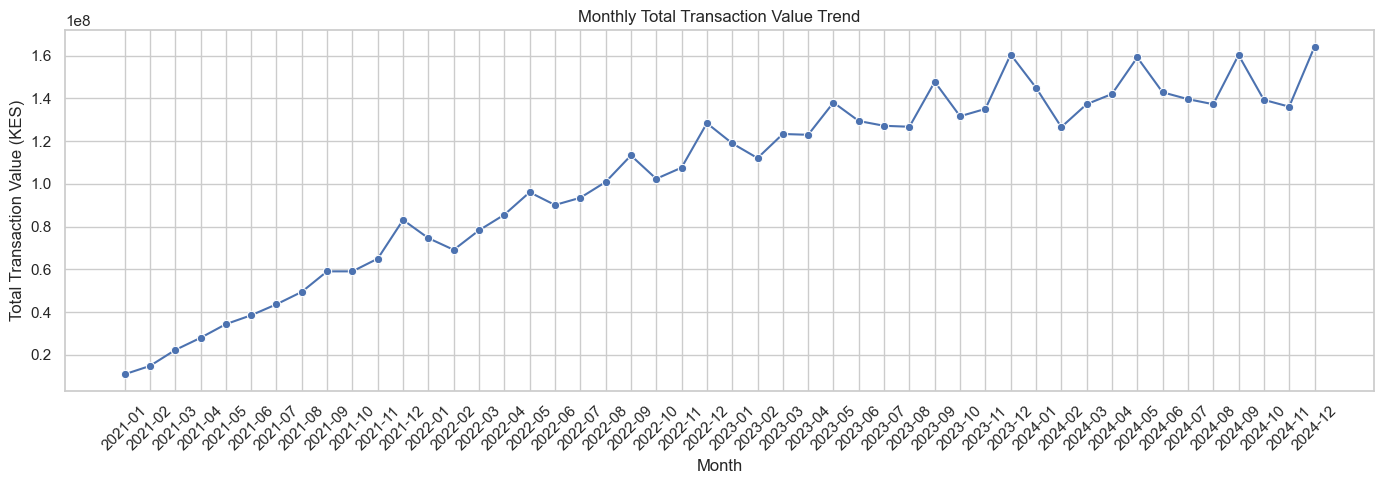

In [30]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_transaction_summary,
    x='txn_month',
    y='Total_Transaction_Value',
    marker='o'
)

plt.title('Monthly Total Transaction Value Trend')
plt.xlabel('Month')
plt.ylabel('Total Transaction Value (KES)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Monthly Transaction Count - Key Observations:**

- Monthly transaction count increased from 149 in January 2021 to 3,346 in December 2024.
- September 2024 recorded the highest monthly transaction count of 3,538.
- Transaction activity shows an overall upward trend with month-to-month fluctuations.

**Monthly Transaction Value - Key Observations:**

- Monthly transaction value increased from approximately KES 10.85 million in January 2021 to KES 164.18 million in December 2024.
- December 2024 recorded the highest monthly transaction value.
- Transaction value generally increased over the analysis period, with some monthly fluctuations.

**Business Interpretation:**

Both monthly transaction count and total transaction value show an overall upward trend. This indicates increasing transaction activity across the observed banking accounts. Monitoring both metrics helps the bank understand changes in transaction volume and monetary activity over time.

### 7.8 Transaction Analysis — Account-Level Behaviour

In [31]:
account_transaction_summary = (
    transactions.groupby('account_id')
    .agg(
        Transaction_Count=('transaction_id', 'count'),
        Total_Transaction_Value=('amount_kes', 'sum'),
        Average_Transaction_Value=('amount_kes', 'mean')
    )
    .reset_index()
)

account_transaction_summary.sort_values(
    'Total_Transaction_Value',
    ascending=False
).head(10)

,account_id,Transaction_Count,Total_Transaction_Value,Average_Transaction_Value
103,2104,153,32697882,213711.647059
392,2393,106,30761400,290201.886792
732,2733,156,27911995,178923.044872
867,2868,180,24554050,136411.388889
325,2326,125,24148443,193187.544000
689,2690,147,23622870,160699.795918
434,2435,220,22167040,100759.272727
489,2490,103,22069965,214271.504854
883,2884,127,21552256,169702.803150
164,2165,145,20506907,141426.944828


**Key Observations:**

- Account 103 has the highest total transaction value among the top 10 accounts, approximately KES 32.70 million.
- Account 883 records the highest transaction count among these accounts, with 2,884 transactions.
- Account 392 has the highest average transaction value, approximately KES 290,202.
- Transaction frequency and average transaction value vary across accounts.

**Business Interpretation:**

Different accounts demonstrate different transaction behaviours. Some accounts generate higher transaction volumes, while others generate higher monetary values per transaction. Analysing both dimensions can help identify accounts with different banking activity patterns.

### Top 10 Accounts by Transaction Count

In [32]:
top_accounts_by_count = (
    account_transaction_summary
    .sort_values('Transaction_Count', ascending=False)
    .head(10)
)

top_accounts_by_count

,account_id,Transaction_Count,Total_Transaction_Value,Average_Transaction_Value
107,2108,286,7495916,26209.496503
812,2813,258,4253257,16485.492248
151,2152,250,9304534,37218.136000
368,2369,235,3285708,13981.736170
322,2323,235,4722864,20097.293617
337,2338,230,13046737,56724.943478
7,2008,229,11733331,51237.253275
547,2548,227,12794289,56362.506608
745,2746,223,10852426,48665.587444
136,2137,223,5782143,25928.892377


**Key Observations:**

- Account 812 has the highest transaction count among all accounts, with 2,813 transactions.
- Account 745 and Account 547 follow with 2,746 and 2,548 transactions, respectively.
- The top 10 accounts by transaction count are different from the top 10 accounts by total transaction value.
- Account 812 records 2,813 transactions but has a total transaction value of approximately KES 4.25 million.
- Account 103 has the highest total transaction value among the top 10 value-generating accounts.

**Business Interpretation:**

Transaction frequency and monetary value represent different dimensions of account activity. Some accounts generate frequent transactions with relatively lower monetary values, while others generate fewer transactions with higher monetary values. Analysing both metrics helps identify different account behaviour patterns.

### 7.9 Relationship between Transaction Count and Value

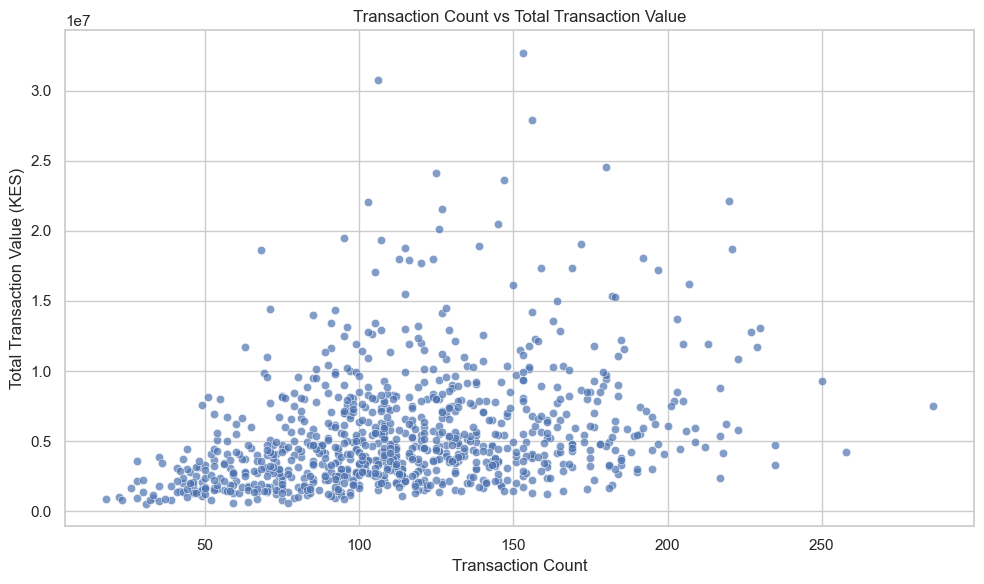

In [33]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=account_transaction_summary,
    x='Transaction_Count',
    y='Total_Transaction_Value',
    alpha=0.7
)

plt.title('Transaction Count vs Total Transaction Value')
plt.xlabel('Transaction Count')
plt.ylabel('Total Transaction Value (KES)')

plt.tight_layout()
plt.show()

**Key Observations:**

- Most accounts have approximately 50–150 transactions.
- Most accounts generate total transaction values below KES 10 million.
- The scatter plot indicates a generally positive association between transaction count and total transaction value.
- Accounts with similar transaction counts can have significantly different total transaction values.
- Some accounts generate high monetary values despite having moderate transaction counts.

**Business Interpretation:**

Transaction frequency and total transaction value generally move in the same direction, but the relationship is not uniform across accounts. Average transaction value also influences the overall monetary contribution of an account. Therefore, both transaction frequency and transaction value should be considered when analysing account activity.

#### actual correlation

In [34]:
correlation = account_transaction_summary[
    ['Transaction_Count', 'Total_Transaction_Value']
].corr()

correlation

,Transaction_Count,Total_Transaction_Value
Transaction_Count,1.000000,0.327776
Total_Transaction_Value,0.327776,1.000000


**Correlation Analysis:**

- The correlation coefficient between Transaction Count and Total Transaction Value is 0.328.
- This indicates a weak positive linear relationship between the two variables.
- Accounts with higher transaction counts tend to have somewhat higher total transaction values, but the relationship is not strong.
- Transaction frequency alone does not fully explain the monetary value generated by an account.

**Business Interpretation:**

Transaction frequency has some positive association with total transaction value. However, accounts with similar transaction counts can generate different monetary values. Therefore, the bank should consider both transaction frequency and average transaction value when evaluating account activity.

# Monthly Credit & Debit Summary

In [35]:
monthly_type_summary = (
    transactions
    .groupby([
        pd.Grouper(key='txn_date', freq='MS'),
        'txn_type'
    ])
    .agg(
        Transaction_Count=('transaction_id', 'count'),
        Total_Transaction_Value=('amount_kes', 'sum')
    )
    .reset_index()
)

monthly_type_summary

,txn_date,txn_type,Transaction_Count,Total_Transaction_Value
0,2021-01-01,CREDIT,94,8415351
1,2021-01-01,DEBIT,55,2438477
2,2021-02-01,CREDIT,152,10081402
3,2021-02-01,DEBIT,129,4673177
4,2021-03-01,CREDIT,253,14619826
...,...,...,...,...
91,2024-10-01,DEBIT,1808,60146826
92,2024-11-01,CREDIT,1113,76459022
93,2024-11-01,DEBIT,1849,59683340
94,2024-12-01,CREDIT,1409,90769982


### Monthly CREDIT vs DEBIT Transaction Count

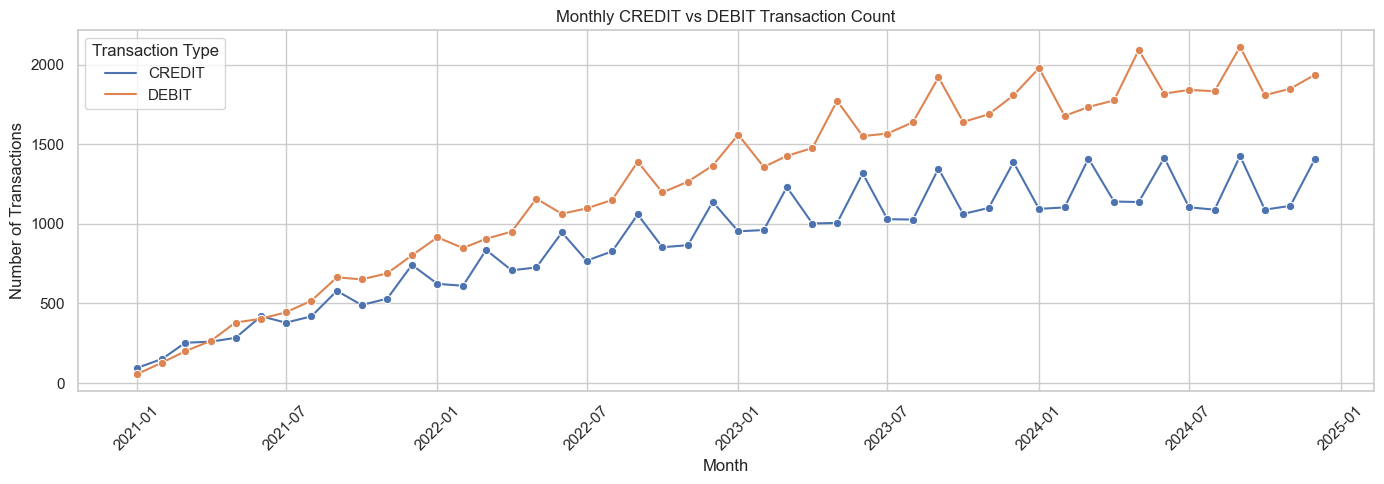

In [36]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_type_summary,
    x='txn_date',
    y='Transaction_Count',
    hue='txn_type',
    marker='o'
)

plt.title('Monthly CREDIT vs DEBIT Transaction Count')
plt.xlabel('Month')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)
plt.legend(title='Transaction Type')

plt.tight_layout()
plt.show()

**Key Observations:**

- DEBIT transactions generally exceed CREDIT transactions across the analysis period.
- Both CREDIT and DEBIT transaction counts show an overall upward trend.
- DEBIT transactions reached 1,937 in December 2024.
- CREDIT transactions reached 1,409 in December 2024.
- Monthly transaction counts fluctuate over time for both transaction types.

**Business Interpretation:**

The dataset shows higher debit-side transaction frequency compared to credit-side frequency. Both transaction types demonstrate increasing activity over the analysis period. Monitoring these trends can help the bank understand changes in transaction behaviour.

### Monthly CREDIT vs DEBIT Transaction Value

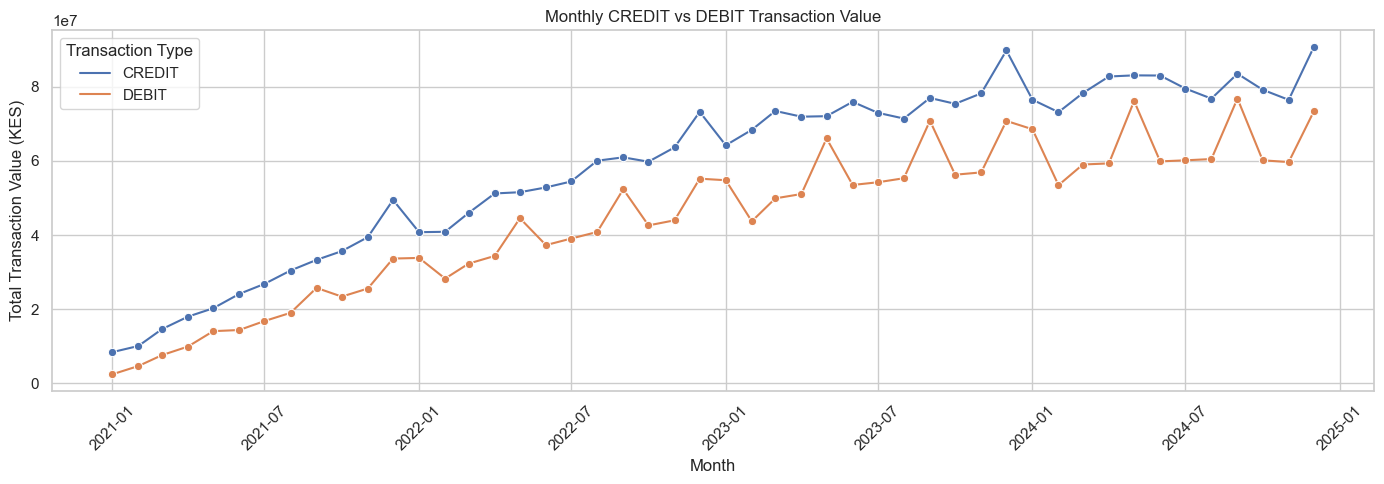

In [37]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_type_summary,
    x='txn_date',
    y='Total_Transaction_Value',
    hue='txn_type',
    marker='o'
)

plt.title('Monthly CREDIT vs DEBIT Transaction Value')
plt.xlabel('Month')
plt.ylabel('Total Transaction Value (KES)')
plt.xticks(rotation=45)
plt.legend(title='Transaction Type')

plt.tight_layout()
plt.show()

**Key Observations:**

- Monthly CREDIT transaction value remains higher than DEBIT transaction value throughout the analysis period.
- Both CREDIT and DEBIT transaction values show an overall upward trend.
- CREDIT transaction value reached approximately KES 90.77 million in December 2024.
- DEBIT transaction value reached approximately KES 73.41 million in December 2024.
- Both transaction types experience month-to-month fluctuations.

**Business Interpretation:**

CREDIT transactions contribute higher monetary value despite having lower transaction frequency than DEBIT transactions. This indicates that debit-side activity is more frequent, while credit-side activity involves higher monetary values. Monitoring both transaction count and transaction value provides a more complete understanding of banking activity.

### Monthly Net Transaction Flow

In [38]:
 monthly_flow = (
    monthly_type_summary
    .pivot(
        index='txn_date',
        columns='txn_type',
        values='Total_Transaction_Value'
    )
    .reset_index()
)

monthly_flow['Net_Transaction_Flow'] = (
    monthly_flow['CREDIT'] - monthly_flow['DEBIT']
)

monthly_flow.head()

txn_type,txn_date,CREDIT,DEBIT,Net_Transaction_Flow
0,2021-01-01,8415351,2438477,5976874
1,2021-02-01,10081402,4673177,5408225
2,2021-03-01,14619826,7602174,7017652
3,2021-04-01,17992638,9924551,8068087
4,2021-05-01,20249301,14072817,6176484


### Net Transaction Flow Visualization

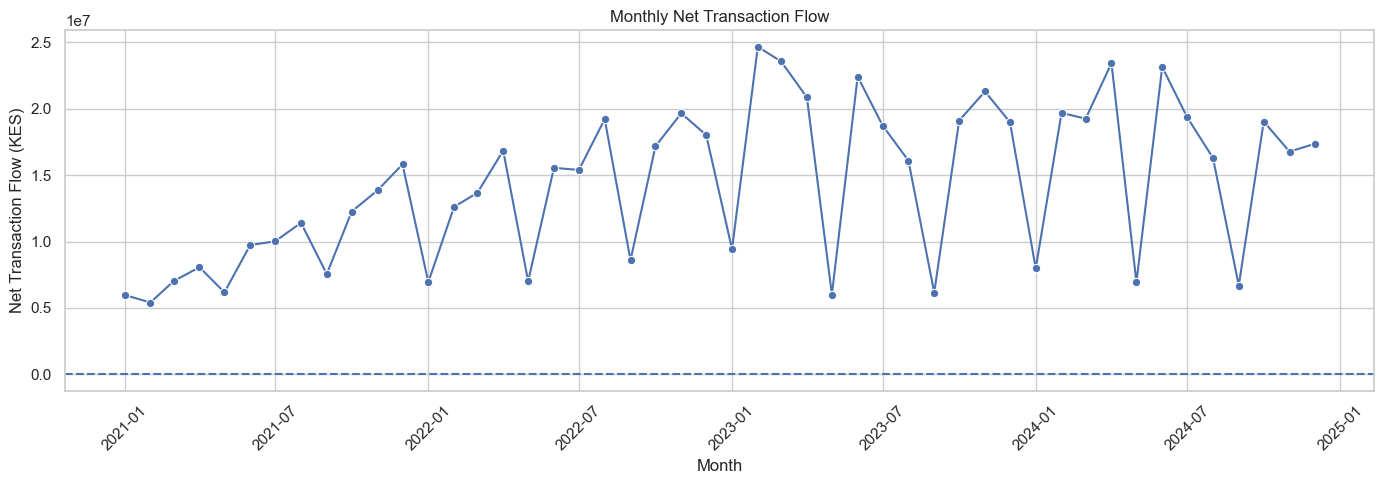

In [39]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_flow,
    x='txn_date',
    y='Net_Transaction_Flow',
    marker='o'
)

plt.axhline(y=0, linestyle='--')

plt.title('Monthly Net Transaction Flow')
plt.xlabel('Month')
plt.ylabel('Net Transaction Flow (KES)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Key Observations:**

- Monthly Net Transaction Flow remained positive throughout the analysis period.
- CREDIT transaction value exceeded DEBIT transaction value in every observed month.
- Net transaction flow showed an overall upward movement with noticeable monthly fluctuations.
- February 2023 recorded the highest net transaction flow, approximately KES 24.6 million.
- Monthly net flow continued to fluctuate during 2024.

**Business Interpretation:**

The bank's recorded CREDIT transaction value consistently exceeded its DEBIT transaction value throughout the observed period. This resulted in a positive monthly transaction-value difference. Monitoring this metric helps understand the relationship between recorded credit and debit activity, but it does not represent bank profit or actual liquidity.

In [40]:
monthly_flow['Total_Transaction_Value'] = (
    monthly_flow['CREDIT'] + monthly_flow['DEBIT']
)

monthly_flow['CREDIT_Share'] = (
    monthly_flow['CREDIT']
    / monthly_flow['Total_Transaction_Value'] * 100
).round(2)

monthly_flow['DEBIT_Share'] = (
    monthly_flow['DEBIT']
    / monthly_flow['Total_Transaction_Value'] * 100
).round(2)

monthly_flow.head()

txn_type,txn_date,CREDIT,DEBIT,Net_Transaction_Flow,Total_Transaction_Value,CREDIT_Share,DEBIT_Share
0,2021-01-01,8415351,2438477,5976874,10853828,77.53,22.47
1,2021-02-01,10081402,4673177,5408225,14754579,68.33,31.67
2,2021-03-01,14619826,7602174,7017652,22222000,65.79,34.21
3,2021-04-01,17992638,9924551,8068087,27917189,64.45,35.55
4,2021-05-01,20249301,14072817,6176484,34322118,59.00,41.00


**Key Observations:**

- CREDIT transactions contributed 77.53% of total transaction value in January 2021.
- DEBIT transactions contributed 22.47% in January 2021.
- CREDIT share decreased from 77.53% in January to 59.00% in May 2021.
- DEBIT share increased from 22.47% in January to 41.00% in May 2021.
- CREDIT and DEBIT shares together account for 100% of monthly transaction value.

**Business Interpretation:**

The monthly transaction-value composition helps identify the relative contribution of CREDIT and DEBIT transactions. In the first five months of the observed period, the CREDIT share decreased while the DEBIT share increased. The complete analysis period should be considered before drawing an overall conclusion.

In [41]:
monthly_flow[
    ['CREDIT_Share', 'DEBIT_Share']
].mean().round(2)

txn_type
CREDIT_Share    58.3
DEBIT_Share     41.7
dtype: float64

**Average Transaction Value Share:**

- Average monthly CREDIT share is 58.30%.
- Average monthly DEBIT share is 41.70%.
- CREDIT share exceeds DEBIT share by 16.60 percentage points.

**Business Interpretation:**

Across the 48-month analysis period, CREDIT transactions contributed a higher average share of monthly transaction value than DEBIT transactions. This is consistent with the earlier finding that CREDIT transactions have higher average transaction values despite lower transaction frequency.

# Transaction Behaviour Analysis — Conclusion

The transaction analysis reveals the following key findings:

1. A total of 102,880 transactions were recorded, with an aggregate transaction value of approximately KES 4.95 billion.
2. Transaction amounts show a positively skewed distribution, with lower-value transactions occurring more frequently.
3. DEBIT transactions account for 58.68% of transaction volume, while CREDIT transactions account for 41.32%.
4. CREDIT transactions contribute approximately KES 2.82 billion, compared with KES 2.13 billion from DEBIT transactions.
5. M-Pesa is the leading transaction channel by transaction count and total transaction value.
6. Monthly transaction count and total transaction value show an overall upward trend from 2021 to 2024.
7. DEBIT transactions generally occur more frequently, whereas CREDIT transactions contribute higher monetary value.
8. Monthly Net Transaction Flow remained positive throughout the observed period.
9. The average monthly CREDIT and DEBIT transaction-value shares were 58.30% and 41.70%, respectively.
10. Transaction count and total transaction value have a weak positive linear correlation (0.328) across accounts.

**Overall Business Insight:**

The analysis highlights differences in transaction frequency, monetary value, channel usage and account activity. These findings can help the bank understand transaction behaviour and identify opportunities for improving banking services and channel engagement.

**Data Limitation:**

Transactions are recorded at account level. Individual customer attribution is not possible for joint accounts. Transaction-value differences should not be interpreted as bank profit or actual liquidity.

# 8 Loan Portfolio Analysis


**Objective:**

Analyse the bank's loan portfolio to understand loan distribution, outstanding loan statuses, loan amounts, repayment obligations and potential portfolio risks.

**Business Questions:**

- What is the overall distribution of loans by status?
- What are the typical loan amounts and durations?
- How do scheduled monthly payments vary across loans?
- Which customer segments and counties have higher loan participation?
- What potential portfolio risks can be identified from loan status distribution?

**Business Relevance:**

Understanding the loan portfolio can help the bank evaluate lending activity, monitor loan status distribution and identify areas requiring further risk assessment.

**Data Limitation:**

The dataset contains scheduled monthly payment amounts but does not include actual repayment history. Therefore, repayment timeliness and actual repayment performance cannot be measured.

### 8.1 Loan Portfolio Overview

In [42]:
loan_summary = loans[
    ['amount_kes', 'duration_months', 'monthly_payment_kes']
].describe().round(2)

loan_summary

,amount_kes,duration_months,monthly_payment_kes
count,296.00,296.00,296.00
mean,418699.32,24.00,21897.51
std,372036.40,12.02,16724.39
min,48000.00,12.00,2131.00
25%,185250.00,12.00,10562.75
50%,324000.00,24.00,17149.50
75%,512750.00,24.00,28373.00
max,3372000.00,60.00,92145.00


**Key Observations:**

- The dataset contains 296 loan records.
- The average loan amount is KES 418,699.32, while the median is KES 324,000.
- Loan amounts range from KES 48,000 to KES 3,372,000.
- The average and median loan duration are both 24 months.
- The average scheduled monthly payment is KES 21,897.51.
- Loan amounts show considerable variation, with a standard deviation of KES 372,036.40.

**Business Interpretation:**

The loan portfolio contains loans of different sizes and durations. The average loan amount being higher than the median indicates that some comparatively large loans influence the overall average. Understanding this variation can help the bank evaluate its loan portfolio composition.

### 8.2 Loan Status Distribution

In [43]:
loan_status_summary = (
    loans['status']
    .value_counts()
    .reset_index()
)

loan_status_summary.columns = ['Loan Status', 'Loan Count']

loan_status_summary['Percentage'] = (
    loan_status_summary['Loan Count'] / len(loans) * 100
).round(2)

loan_status_summary

,Loan Status,Loan Count,Percentage
0,Current,176,59.46
1,Repaid,74,25.00
2,In arrears,27,9.12
3,Defaulted,19,6.42


**Key Observations:**

- The dataset contains 296 loans.
- Current loans account for 59.46% of the portfolio.
- Repaid loans represent 25.00%.
- In arrears loans account for 9.12%.
- Defaulted loans account for 6.42%.
- A combined 15.54% of loans are classified as In arrears or Defaulted.

**Business Interpretation:**

Most loans are currently classified as Current. However, 46 loans fall into In arrears or Defaulted categories, indicating a segment that may require closer monitoring. Further analysis of loan amounts and customer segments can help understand the distribution of potential portfolio risk.

### Loan Status Visualization

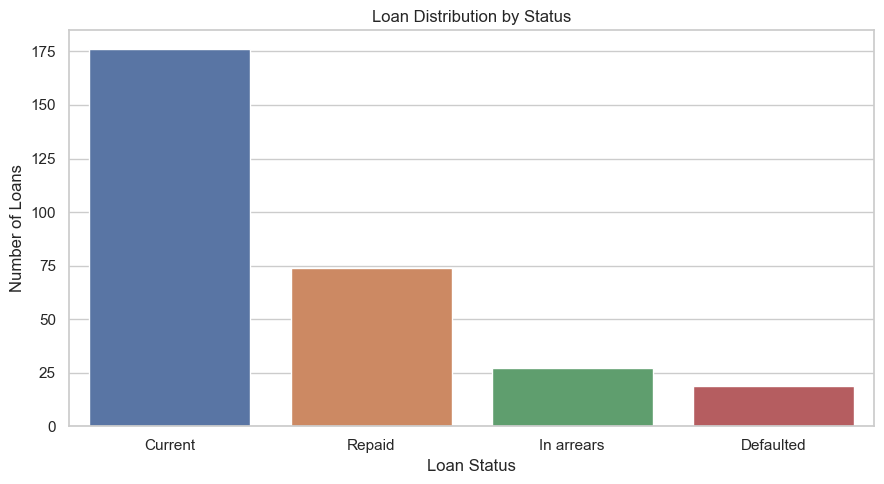

In [44]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=loan_status_summary,
    x='Loan Status',
    y='Loan Count'
)

plt.title('Loan Distribution by Status')
plt.xlabel('Loan Status')
plt.ylabel('Number of Loans')

plt.tight_layout()
plt.show()

### 8.3 Loan Amount Distribution

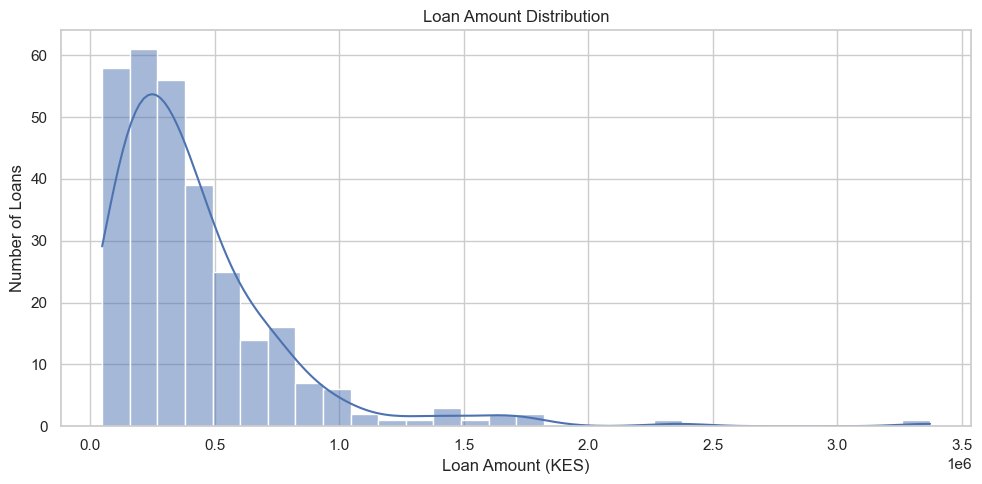

In [45]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=loans,
    x='amount_kes',
    bins=30,
    kde=True
)

plt.title('Loan Amount Distribution')
plt.xlabel('Loan Amount (KES)')
plt.ylabel('Number of Loans')

plt.tight_layout()
plt.show()

**Key Observations:**

- Loan amounts are concentrated mainly in the lower-value ranges.
- Most loans fall approximately between KES 100,000 and KES 500,000.
- The distribution is positively skewed (right-skewed).
- A relatively small number of loans have amounts exceeding KES 1 million.
- The maximum loan amount is KES 3,372,000.

**Business Interpretation:**

The bank's loan portfolio is primarily concentrated in small-to-medium-sized loans. A small number of high-value loans contribute to the right-skewed distribution and influence the average loan amount. These high-value loans can be examined further alongside their loan statuses to understand their portfolio contribution.

### 8.4 Loan Duration Distribution

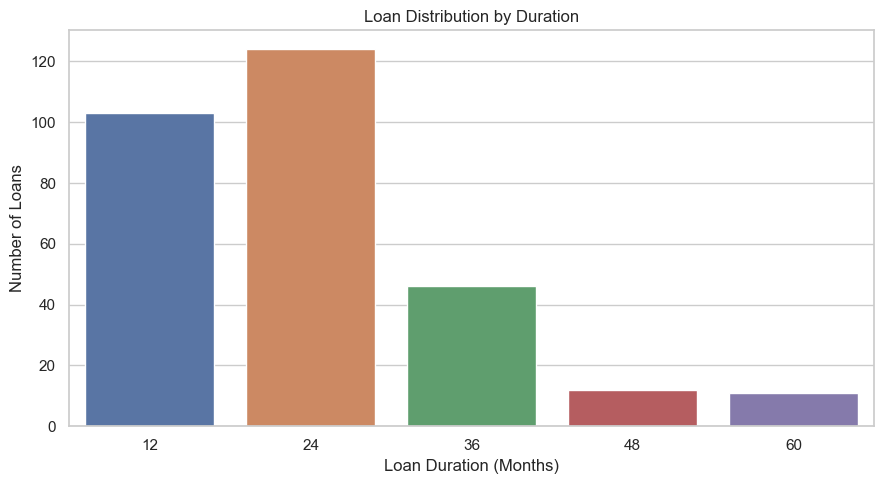

In [46]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=loans,
    x='duration_months'
)

plt.title('Loan Distribution by Duration')
plt.xlabel('Loan Duration (Months)')
plt.ylabel('Number of Loans')

plt.tight_layout()
plt.show()

**Key Observations:**

- 24-month loans represent the largest share of the portfolio.
- 12-month loans are the second most common.
- 36-month loans account for a smaller proportion.
- Only a small number of loans have durations of 48 or 60 months.
- The average and median loan duration are both 24 months.

**Business Interpretation:**

The loan portfolio is primarily concentrated in shorter and medium-term loans, particularly 12-month and 24-month durations. Longer-term loans are relatively uncommon. This information can help the bank understand customer loan tenure preferences and evaluate its loan portfolio structure.

### Scheduled Monthly Payment Distribution

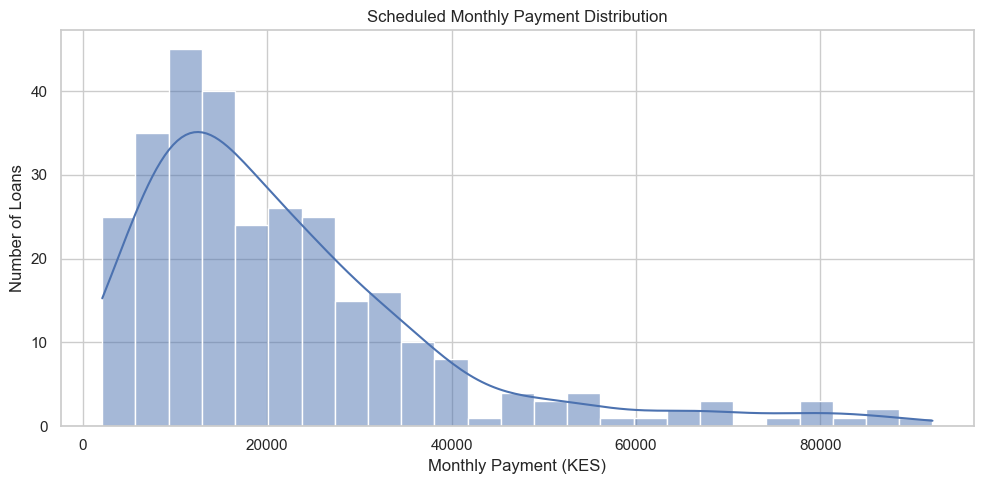

In [47]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=loans,
    x='monthly_payment_kes',
    bins=25,
    kde=True
)

plt.title('Scheduled Monthly Payment Distribution')
plt.xlabel('Monthly Payment (KES)')
plt.ylabel('Number of Loans')

plt.tight_layout()
plt.show()

**Key Observations:**

- Most scheduled monthly payments are concentrated approximately between KES 5,000 and KES 25,000.
- The highest frequency is observed around the KES 10,000–15,000 range.
- The distribution is positively skewed (right-skewed).
- A relatively small number of loans have scheduled monthly payments exceeding KES 50,000.
- The maximum scheduled monthly payment is KES 92,145.

**Business Interpretation:**

Most loans have comparatively lower scheduled monthly payment obligations, while a smaller number have higher payment amounts. This variation helps the bank understand the distribution of scheduled payment obligations across its loan portfolio.

**Data Limitation:**

These values represent scheduled monthly payments, not actual payments received. Therefore, they cannot be used to determine whether customers paid their instalments on time.

### Loan Status vs Loan Amount

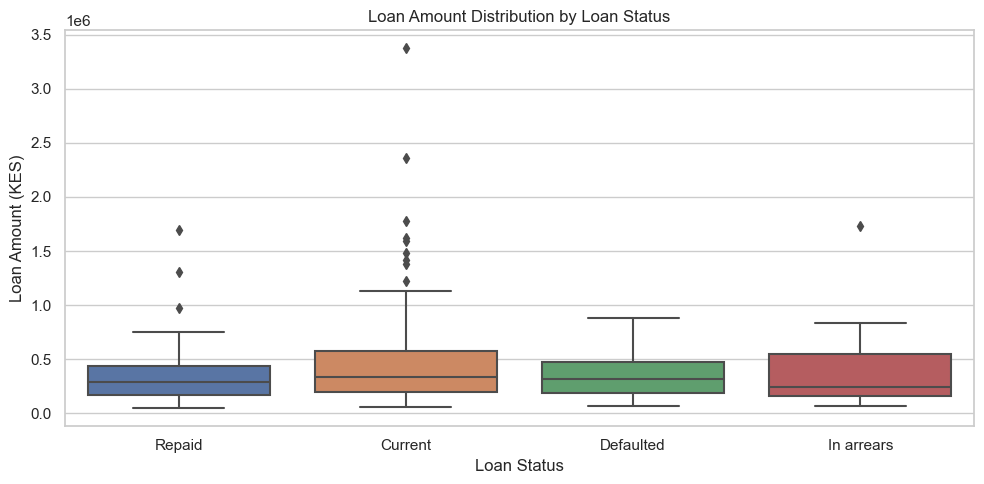

In [48]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=loans,
    x='status',
    y='amount_kes'
)

plt.title('Loan Amount Distribution by Loan Status')
plt.xlabel('Loan Status')
plt.ylabel('Loan Amount (KES)')

plt.tight_layout()
plt.show()

**Key Observations:**

- Current loans show considerable variation in loan amounts.
- Several high-value outliers are observed in the Current and Repaid categories.
- Defaulted loans have a relatively concentrated loan amount distribution.
- In arrears loans show a comparatively lower median loan amount.
- The loan amount distributions overlap across different status categories.

**Business Interpretation:**

Loan amounts vary across different loan status categories. However, the overlapping distributions indicate that loan amount alone does not clearly distinguish between loan statuses. Further analysis of customer and regional characteristics may help identify additional patterns.

**Data Limitation:**

The Defaulted category contains only 19 loans. Therefore, its distribution should be interpreted cautiously. This analysis also does not establish a causal relationship between loan amount and loan status.

### Loan Amount Summary by Status

In [49]:
loan_status_amount_summary = (
    loans.groupby('status')['amount_kes']
    .agg(
        Loan_Count='count',
        Average_Loan_Amount='mean',
        Median_Loan_Amount='median',
        Minimum_Loan_Amount='min',
        Maximum_Loan_Amount='max'
    )
    .round(2)
    .reset_index()
)

loan_status_amount_summary

,status,Loan_Count,Average_Loan_Amount,Median_Loan_Amount,Minimum_Loan_Amount,Maximum_Loan_Amount
0,Current,176,456636.36,337000.0,60000,3372000
1,Defaulted,19,357789.47,321000.0,69000,879000
2,In arrears,27,394333.33,242000.0,67000,1728000
3,Repaid,74,353000.00,290000.0,48000,1698000


**Key Observations:**

- Current loans have the highest average loan amount of KES 456,636.36.
- Current loans also have the highest median loan amount of KES 337,000.
- In arrears loans have an average amount of KES 394,333.33.
- Defaulted loans have a median loan amount of KES 321,000.
- Repaid loans have an average loan amount of KES 353,000.
- The maximum loan amount is KES 3,372,000, observed in the Current category.

**Business Interpretation:**

Loan amounts show variation across different loan status categories. However, loan amount alone does not clearly distinguish between the different statuses. Additional customer and regional analysis may help identify further patterns.

**Data Limitation:**

The Defaulted category contains only 19 loans. Therefore, comparisons involving this category should be interpreted cautiously.

### Regional Loan Analysis

In [50]:
loan_county_data = (
    loans
    .merge(
        accounts[['account_id', 'county_id']],
        on='account_id',
        how='left'
    )
    .merge(
        counties[['county_id', 'county']],
        on='county_id',
        how='left'
    )
)

loan_county_summary = (
    loan_county_data
    .groupby('county')
    .agg(
        Loan_Count=('loan_id', 'count'),
        Total_Loan_Amount=('amount_kes', 'sum'),
        Average_Loan_Amount=('amount_kes', 'mean')
    )
    .sort_values('Loan_Count', ascending=False)
    .round(2)
    .reset_index()
)

loan_county_summary

,county,Loan_Count,Total_Loan_Amount,Average_Loan_Amount
0,Nairobi,62,37783000,609403.23
1,Kiambu,43,21279000,494860.47
2,Mombasa,23,7399000,321695.65
3,Nakuru,23,9474000,411913.04
4,Machakos,20,6473000,323650.00
5,Kakamega,18,5771000,320611.11
6,Kisumu,18,5688000,316000.00
7,Kilifi,14,3785000,270357.14
8,Embu,13,4839000,372230.77
9,Uasin Gishu,13,4965000,381923.08


**Key Observations:**

- Nairobi has the highest loan count with 62 loans (20.95%).
- Kiambu ranks second with 43 loans (14.53%).
- Nairobi has the highest total loan amount of KES 37.78 million.
- Nairobi also has the highest average loan amount of KES 609,403.23.
- Bungoma has the lowest loan count with 7 loans.
- Bungoma has the lowest average loan amount of KES 241,285.71.
- Nairobi and Kiambu together account for 35.47% of the total loans.

**Business Interpretation:**

Loan distribution is concentrated more heavily in Nairobi and Kiambu compared with other counties. Nairobi also records the highest average loan amount. These regional patterns can help the bank identify areas for further investigation and potential lending opportunities.

**Data Limitation:**

County information is derived from the account's county_id. It may not represent the customer's residential location. Loan counts also do not measure county-wise loan adoption rates because the number of customers in each county differs.

### Visualize County-wise Loan Distribution

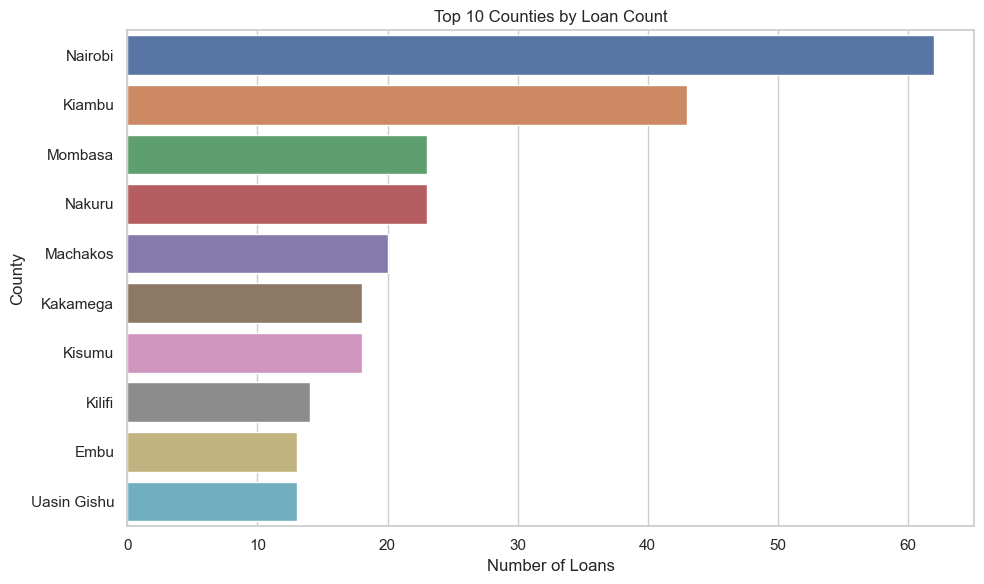

In [51]:
top_loan_counties = loan_county_summary.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_loan_counties,
    x='Loan_Count',
    y='county'
)

plt.title('Top 10 Counties by Loan Count')
plt.xlabel('Number of Loans')
plt.ylabel('County')

plt.tight_layout()
plt.show()

**Chart Interpretation:**

- Nairobi has the highest number of loans, followed by Kiambu.
- Mombasa and Nakuru have an equal number of loans.
- The top two counties, Nairobi and Kiambu, account for 35.47% of all loans.
- Loan distribution varies considerably across counties.

**Business Interpretation:**

Nairobi and Kiambu represent the largest loan markets in the observed dataset. The bank can investigate customer demand, product preferences and lending opportunities across different counties to understand regional differences.

## Loan Portfolio Analysis – Key Findings

1. The dataset contains 296 loan records.
2. The average loan amount is KES 418,699.32.
3. Current loans represent the largest status category (59.46%).
4. A combined 15.54% of loans are classified as In arrears or Defaulted.
5. Loan amounts are positively skewed, with a small number of high-value loans.
6. The most common loan duration is 24 months.
7. Most scheduled monthly payments are concentrated in lower payment ranges.
8. Current loans have the highest average loan amount.
9. Nairobi has the highest loan count (62) and total loan amount.
10. Nairobi and Kiambu together account for 35.47% of all loans.

**Overall Business Insights:**

The bank's loan portfolio is primarily concentrated in Current loans, with 12-month and 24-month durations being the most common. Loan amounts and scheduled monthly payments vary considerably. Nairobi and Kiambu account for a significant share of the observed loan distribution.

These findings can help the bank understand its loan portfolio composition and identify areas for further investigation.

**Limitations:**

- The dataset does not contain actual repayment history.
- Scheduled monthly payments cannot establish repayment performance.
- The Defaulted category has only 19 records.
- County information represents account location, not necessarily customer residence.
- The analysis identifies patterns and associations, not causal relationships.

# 10. Card Adoption Analysis


**Objective:**

Analyse card distribution and customer card adoption patterns to understand the bank's card portfolio and identify potential opportunities to increase card adoption.

**Business Questions:**

- How many cards have been issued by the bank?
- Which card types are most common?
- What percentage of customers have bank cards?
- Which customer segments have lower card adoption?
- How does card adoption vary across different counties?

**Business Relevance:**

Understanding card adoption can help the bank identify customer segments with lower card ownership and explore opportunities to promote suitable banking card products.

**Data Limitation:**

The dataset contains card issuance records but does not include card activation or usage information. Therefore, issued cards cannot automatically be considered active cards.

### 10.1 Card Type Distribution

In [52]:
card_type_summary = (
    cards['card_type']
    .value_counts()
    .reset_index()
)

card_type_summary.columns = ['Card Type', 'Card Count']

card_type_summary['Percentage'] = (
    card_type_summary['Card Count'] / len(cards) * 100
).round(2)

card_type_summary

,Card Type,Card Count,Percentage
0,Classic,177,76.29
1,Youth,29,12.50
2,Gold,26,11.21


**Key Observations:**

- The bank has issued a total of 232 cards.
- Classic cards represent the largest share at 76.29%.
- Youth cards account for 12.50% of issued cards.
- Gold cards account for 11.21% of issued cards.
- Classic cards significantly dominate the overall card portfolio.

**Business Interpretation:**

The bank's card portfolio is heavily concentrated in Classic cards. Youth and Gold cards represent relatively smaller shares. The bank can further investigate opportunities to increase adoption across these card categories.

**Data Limitation:**

The dataset contains card issuance records but does not include activation or usage information. Therefore, card issuance does not necessarily indicate active card usage.

### 10.2 Card Type Distribution Chart

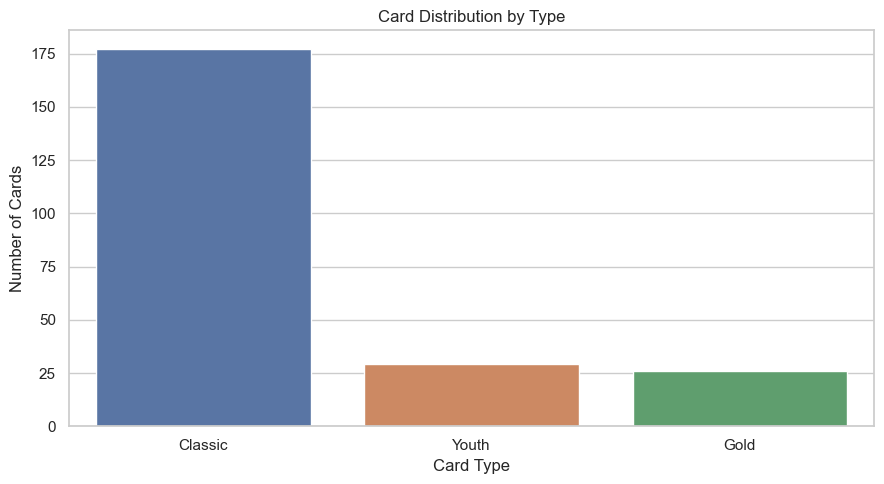

In [53]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=card_type_summary,
    x='Card Type',
    y='Card Count'
)

plt.title('Card Distribution by Type')
plt.xlabel('Card Type')
plt.ylabel('Number of Cards')

plt.tight_layout()
plt.show()

**Chart Interpretation:**

- Classic cards significantly dominate the card portfolio.
- Youth and Gold cards have considerably lower issuance counts.
- The difference between Youth and Gold card counts is relatively small.

**Business Interpretation:**

The bank's card issuance is concentrated in Classic cards. Further customer-level analysis can help identify segments with lower card ownership and potential opportunities to improve card adoption.

### 10.3 Customer Card Mapping

In [54]:
customer_card_data = (
    account_holders
    .merge(
        cards[['holder_id', 'card_id']],
        on='holder_id',
        how='left'
    )
)

customer_card_data.head()

,holder_id,account_id,customer_id,holder_type,card_id
0,30001,2001,10001,OWNER,NaN
1,30002,2002,10002,OWNER,NaN
2,30003,2002,10003,JOINT,NaN
3,30004,2003,10004,OWNER,50001.0
4,30005,2004,10005,OWNER,NaN


### Relationship verify karo

In [55]:
print("Account Holders:")
print(account_holders.head())

print("\nCards:")
print(cards.head())

print("\nAccount Holder Columns:")
print(account_holders.columns.tolist())

print("\nCards Columns:")
print(cards.columns.tolist())

Account Holders:
   holder_id  account_id  customer_id holder_type
0      30001        2001        10001       OWNER
1      30002        2002        10002       OWNER
2      30003        2002        10003       JOINT
3      30004        2003        10004       OWNER
4      30005        2004        10005       OWNER

Cards:
   card_id  holder_id card_type issued_date
0    50001      30004   Classic  2022-12-29
1    50002      30006   Classic  2024-07-27
2    50003      30009     Youth  2022-08-11
3    50004      30010   Classic  2022-11-04
4    50005      30013   Classic  2024-04-13

Account Holder Columns:
['holder_id', 'account_id', 'customer_id', 'holder_type']

Cards Columns:
['card_id', 'holder_id', 'card_type', 'issued_date']


### 10.4 Customer Card Adoption Summary

In [56]:
customer_card_summary = (
    customer_card_data
    .groupby('customer_id')
    .agg(
        Has_Card=('card_id', lambda x: x.notna().any())
    )
    .reset_index()
)

total_customers = customers['customer_id'].nunique()

customers_with_cards = customer_card_summary['Has_Card'].sum()

customers_without_cards = (
    total_customers - customers_with_cards
)

card_adoption_summary = pd.DataFrame({
    'Metric': [
        'Total Customers',
        'Customers With Cards',
        'Customers Without Cards',
        'Card Adoption Rate (%)',
        'Customers Without Cards (%)'
    ],
    'Value': [
        total_customers,
        customers_with_cards,
        customers_without_cards,
        round(customers_with_cards / total_customers * 100, 2),
        round(customers_without_cards / total_customers * 100, 2)
    ]
})

card_adoption_summary

,Metric,Value
0,Total Customers,1034.00
1,Customers With Cards,232.00
2,Customers Without Cards,802.00
3,Card Adoption Rate (%),22.44
4,Customers Without Cards (%),77.56


**Key Observations:**

- The bank has a total of 1,034 customers.
- 232 customers have at least one issued card record.
- 802 customers do not have an associated issued card record.
- The overall card adoption rate is 22.44%.
- 77.56% of customers do not have an associated issued card record.

**Business Interpretation:**

The customer card adoption rate is relatively low, with only 22.44% of customers having an issued card record. A large proportion of customers (77.56%) do not have an associated card record. This represents a potential opportunity for the bank to investigate suitable customer segments for card promotion.

**Data Limitation:**

The analysis identifies card issuance, not card activation or actual usage. Customers without an associated card record are considered customers without an issued card in the available dataset.

### 10.5 Card Adoption by Gender

In [57]:
customer_card_gender = (
    customer_card_summary
    .merge(
        customers[['customer_id', 'gender']],
        on='customer_id',
        how='left'
    )
)

gender_card_summary = (
    customer_card_gender
    .groupby('gender')
    .agg(
        Total_Customers=('customer_id', 'nunique'),
        Customers_With_Cards=('Has_Card', 'sum')
    )
    .reset_index()
)

gender_card_summary['Customers_Without_Cards'] = (
    gender_card_summary['Total_Customers']
    - gender_card_summary['Customers_With_Cards']
)

gender_card_summary['Card_Adoption_Rate'] = (
    gender_card_summary['Customers_With_Cards']
    / gender_card_summary['Total_Customers'] * 100
).round(2)

gender_card_summary

,gender,Total_Customers,Customers_With_Cards,Customers_Without_Cards,Card_Adoption_Rate
0,Female,492,117,375,23.78
1,Male,542,115,427,21.22


**Key Observations:**

- Female customers have a card adoption rate of 23.78%.
- Male customers have a card adoption rate of 21.22%.
- Female card adoption is higher by 2.56 percentage points.
- 375 Female customers and 427 Male customers do not have an associated issued card record.
- Both gender groups have relatively low card adoption rates.

**Business Interpretation:**

Female customers show slightly higher card adoption compared with Male customers. However, the adoption rates are relatively low for both groups. The bank can investigate additional customer characteristics and banking behaviour to identify suitable card promotion opportunities.

#### Gender-wise Card Adoption Chart

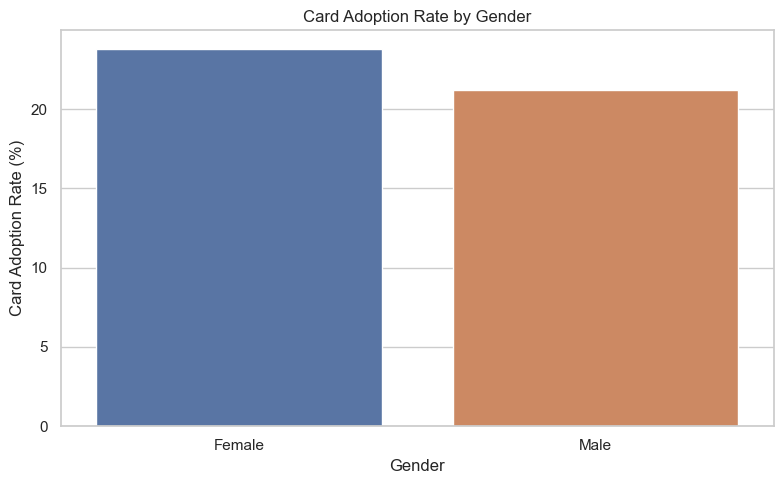

In [58]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=gender_card_summary,
    x='gender',
    y='Card_Adoption_Rate'
)

plt.title('Card Adoption Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Card Adoption Rate (%)')

plt.tight_layout()
plt.show()

**Chart Interpretation:**

- Female customers have a higher card adoption rate than Male customers.
- The difference in adoption rates is 2.56 percentage points.
- Both gender groups show relatively low card adoption.

**Business Interpretation:**

The chart indicates a slightly higher card adoption rate among Female customers. However, the difference is not substantial enough to establish gender as a major factor influencing card adoption. Further analysis of customer characteristics and banking behaviour is required.

### 10.6 County-wise Card Adoption Analysis

In [59]:
customer_card_county = (
    customer_card_summary
    .merge(
        customers[['customer_id', 'county_id']],
        on='customer_id',
        how='left'
    )
    .merge(
        counties[['county_id', 'county']],
        on='county_id',
        how='left'
    )
)

customer_card_county.head()

,customer_id,Has_Card,county_id,county
0,10001,False,6,Uasin Gishu
1,10002,False,1,Nairobi
2,10003,False,1,Nairobi
3,10004,True,2,Kiambu
4,10005,False,2,Kiambu


### County-wise Card Adoption Rate

In [60]:
county_card_summary = (
    customer_card_county
    .groupby('county')
    .agg(
        Total_Customers=('customer_id', 'nunique'),
        Customers_With_Cards=('Has_Card', 'sum')
    )
    .reset_index()
)

county_card_summary['Customers_Without_Cards'] = (
    county_card_summary['Total_Customers']
    - county_card_summary['Customers_With_Cards']
)

county_card_summary['Card_Adoption_Rate'] = (
    county_card_summary['Customers_With_Cards']
    / county_card_summary['Total_Customers'] * 100
).round(2)

county_card_summary = county_card_summary.sort_values(
    'Card_Adoption_Rate',
    ascending=False
)

county_card_summary

,county,Total_Customers,Customers_With_Cards,Customers_Without_Cards,Card_Adoption_Rate
6,Kisii,26,8,18,30.77
0,Bungoma,30,9,21,30.00
7,Kisumu,62,18,44,29.03
5,Kilifi,53,15,38,28.30
1,Embu,39,10,29,25.64
4,Kiambu,126,30,96,23.81
9,Meru,49,11,38,22.45
10,Mombasa,77,17,60,22.08
14,Uasin Gishu,50,11,39,22.00
11,Nairobi,226,47,179,20.80


**Key Observations:**

- Kisii has the highest card adoption rate at 30.77%.
- Bungoma ranks second with an adoption rate of 30.00%.
- Kisumu and Kilifi have adoption rates of 29.03% and 28.30%, respectively.
- Machakos has the lowest adoption rate at 15.38%.
- Nairobi has the highest customer count (226) but an adoption rate of 20.80%.
- Card adoption rates vary across different counties.

**Business Interpretation:**

Card adoption varies across counties. Kisii, Bungoma, Kisumu and Kilifi show comparatively higher adoption rates, while Machakos and Kakamega have lower rates. Nairobi has the largest customer base but does not have the highest adoption rate.

The bank can investigate counties with lower adoption rates to identify potential opportunities for card promotion.

**Data Limitation:**

Some counties have relatively small customer samples. Therefore, adoption rates should be interpreted cautiously. County information represents account location and may not represent customer residence.

### County-wise Card Adoption Chart

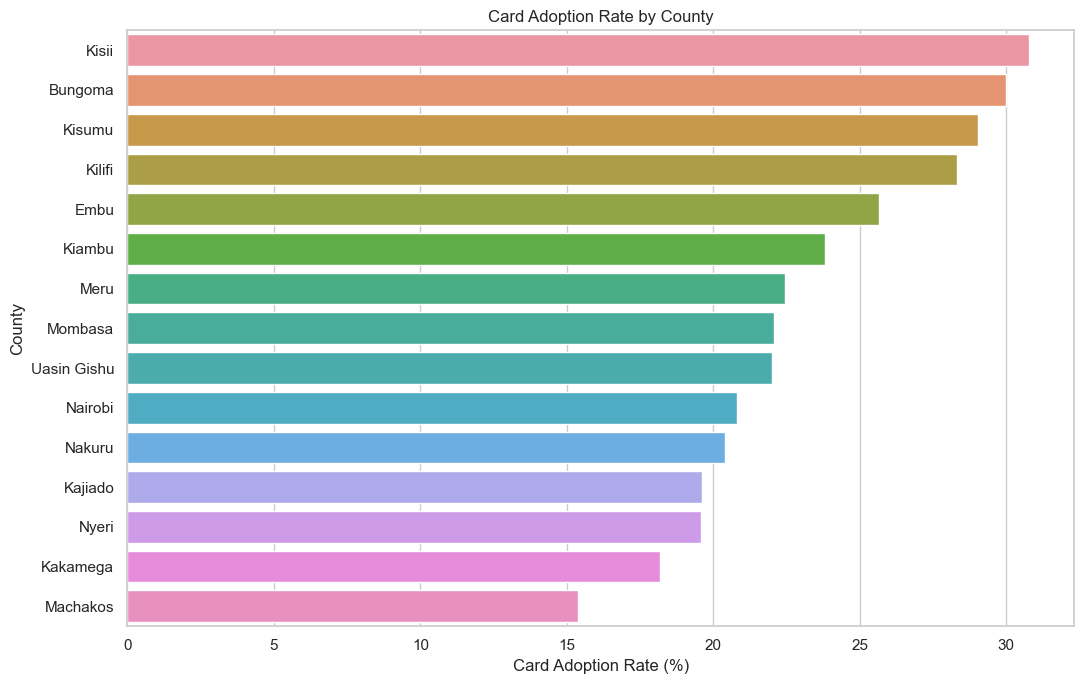

In [61]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=county_card_summary,
    x='Card_Adoption_Rate',
    y='county'
)

plt.title('Card Adoption Rate by County')
plt.xlabel('Card Adoption Rate (%)')
plt.ylabel('County')

plt.tight_layout()
plt.show()

**Chart Interpretation:**

- Kisii has the highest card adoption rate, followed by Bungoma.
- Kisumu and Kilifi also show relatively higher adoption rates.
- Machakos has the lowest card adoption rate.
- Nairobi has the largest customer base but a relatively lower adoption rate.
- Card adoption varies across all 15 counties.

**Business Interpretation:**

The chart highlights regional differences in card adoption. Counties with lower adoption rates may provide opportunities for further investigation and targeted card promotion. However, customer population and sample size should also be considered before making regional business decisions.

# Card Adoption Analysis – Conclusion

### Card Adoption Analysis – Key Findings

1. The bank has issued 232 cards across three card categories.
2. Classic cards dominate the portfolio with 76.29%.
3. Only 232 out of 1,034 customers have an associated issued card record.
4. The overall card adoption rate is 22.44%.
5. Approximately 77.56% of customers do not have an associated issued card record.
6. Female customers have a slightly higher adoption rate (23.78%) than Male customers (21.22%).
7. Kisii has the highest county-wise adoption rate at 30.77%.
8. Machakos has the lowest county-wise adoption rate at 15.38%.
9. Nairobi has the largest customer base but an adoption rate of 20.80%.

**Overall Business Insights:**

The bank's card portfolio is heavily concentrated in Classic cards, while overall customer card adoption remains relatively low. Female customers show slightly higher adoption than Male customers. Regional analysis also highlights differences in card adoption across counties.

The bank can investigate customer segments and regions with lower card adoption to identify suitable opportunities for card promotion.

**Limitations:**

- Card issuance does not confirm card activation or usage.
- County information represents account location, not necessarily customer residence.
- Some counties have relatively small customer samples.
- The analysis identifies adoption patterns, not the reasons behind them.

# 11 Regional Analysis


**Objective:**

Analyse customer distribution, banking activity and product adoption across different counties to understand regional patterns and identify potential business opportunities.

**Business Questions:**

- How are customers distributed across different counties?
- Which counties have the highest number of bank accounts?
- How does transaction activity vary across counties?
- How does loan distribution vary across regions?
- Which counties show potential opportunities for banking product adoption?
- How do regional characteristics relate to banking activity?

**Business Relevance:**

Regional analysis helps the bank understand geographical differences in customer distribution and banking activity. These insights can support regional planning, customer targeting and identification of potential business opportunities.

**Data Limitation:**

County information is based on account and customer records. Account location may not necessarily represent the customer's residential location. Regional comparisons should also consider differences in customer counts and population.

### 11.1 Customer Distribution by County

In [62]:
customer_county_summary = (
    customers
    .merge(
        counties[['county_id', 'county']],
        on='county_id',
        how='left'
    )
    .groupby('county')
    .agg(
        Total_Customers=('customer_id', 'nunique')
    )
    .reset_index()
    .sort_values(
        'Total_Customers',
        ascending=False
    )
)

customer_county_summary['Customer_Percentage'] = (
    customer_county_summary['Total_Customers']
    / customers['customer_id'].nunique() * 100
).round(2)

customer_county_summary

,county,Total_Customers,Customer_Percentage
11,Nairobi,226,21.86
4,Kiambu,126,12.19
12,Nakuru,103,9.96
10,Mombasa,77,7.45
7,Kisumu,62,6.00
5,Kilifi,53,5.13
8,Machakos,52,5.03
2,Kajiado,51,4.93
14,Uasin Gishu,50,4.84
9,Meru,49,4.74


**Key Observations:**

- Nairobi has the highest customer count with 226 customers (21.86%).
- Kiambu ranks second with 126 customers (12.19%).
- Nakuru ranks third with 103 customers (9.96%).
- The top three counties account for approximately 44.01% of the total customer base.
- Kisii has the lowest customer count with 26 customers (2.51%).
- Customer distribution varies across the 15 counties.

**Business Interpretation:**

The bank's customer base is concentrated more heavily in Nairobi, Kiambu and Nakuru. Other counties have comparatively smaller customer representation. These regional patterns can help the bank identify areas for further market investigation and potential customer acquisition opportunities.

### Customer Distribution Chart

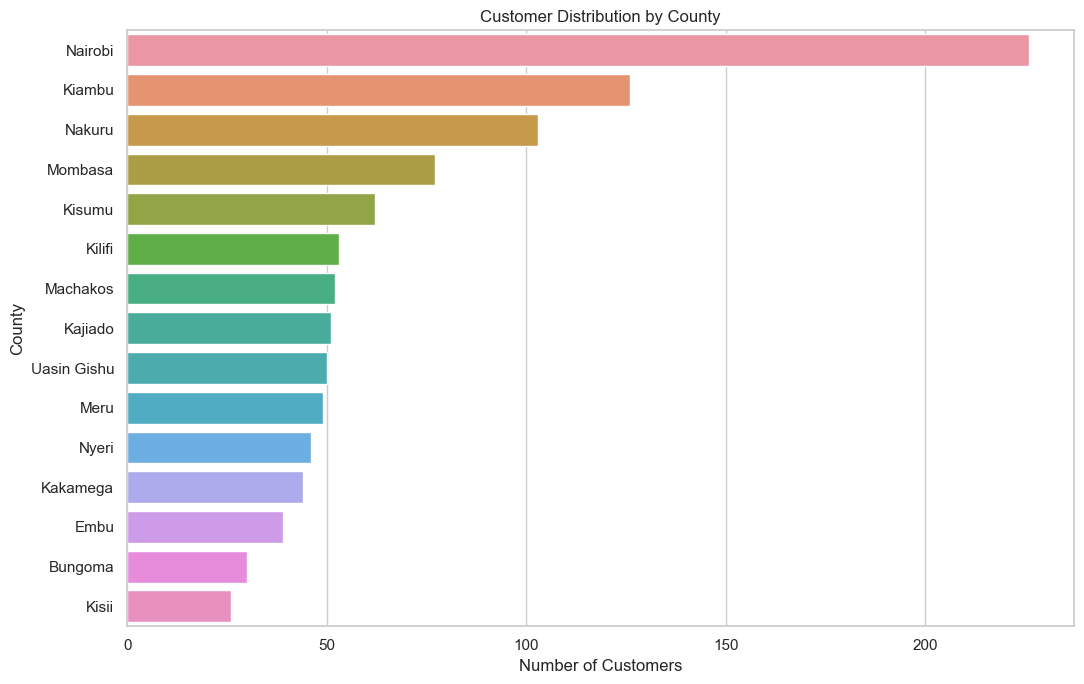

In [63]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=customer_county_summary,
    x='Total_Customers',
    y='county'
)

plt.title('Customer Distribution by County')
plt.xlabel('Number of Customers')
plt.ylabel('County')

plt.tight_layout()
plt.show()

**Chart Interpretation:**

- Nairobi has the highest customer representation, followed by Kiambu and Nakuru.
- Mombasa and Kisumu also have considerable customer representation.
- Kisii has the lowest customer count.
- Customer distribution is concentrated more heavily in the top three counties.

**Business Interpretation:**

The bank's customer base is concentrated in Nairobi, Kiambu and Nakuru. Counties with lower customer representation may provide opportunities for further market investigation and customer acquisition strategies.

### 11.2 Account Distribution by County

In [64]:
account_county_summary = (
    accounts
    .merge(
        counties[['county_id', 'county']],
        on='county_id',
        how='left'
    )
    .groupby('county')
    .agg(
        Total_Accounts=('account_id', 'nunique')
    )
    .reset_index()
    .sort_values(
        'Total_Accounts',
        ascending=False
    )
)

account_county_summary['Account_Percentage'] = (
    account_county_summary['Total_Accounts']
    / accounts['account_id'].nunique() * 100
).round(2)

account_county_summary

,county,Total_Accounts,Account_Percentage
11,Nairobi,200,22.22
4,Kiambu,111,12.33
12,Nakuru,81,9.00
10,Mombasa,72,8.00
5,Kilifi,49,5.44
8,Machakos,49,5.44
7,Kisumu,46,5.11
3,Kakamega,45,5.00
14,Uasin Gishu,45,5.00
9,Meru,41,4.56


**Key Observations:**

- Nairobi has the highest account count with 200 accounts (22.22%).
- Kiambu ranks second with 111 accounts (12.33%).
- Nakuru ranks third with 81 accounts (9.00%).
- Bungoma and Kisii have the lowest account counts with 26 accounts each.
- The top three counties account for approximately 43.56% of all accounts.
- Account distribution broadly follows the customer distribution pattern.

**Business Interpretation:**

The bank's account distribution is concentrated more heavily in Nairobi, Kiambu and Nakuru. These counties also have the largest customer representation. Comparing customer and account distributions helps the bank understand regional differences in banking relationships.

**Data Limitation:**

Customer count and account count are different measures. Joint accounts and multiple banking relationships may affect their comparison.

### Account Distribution Chart

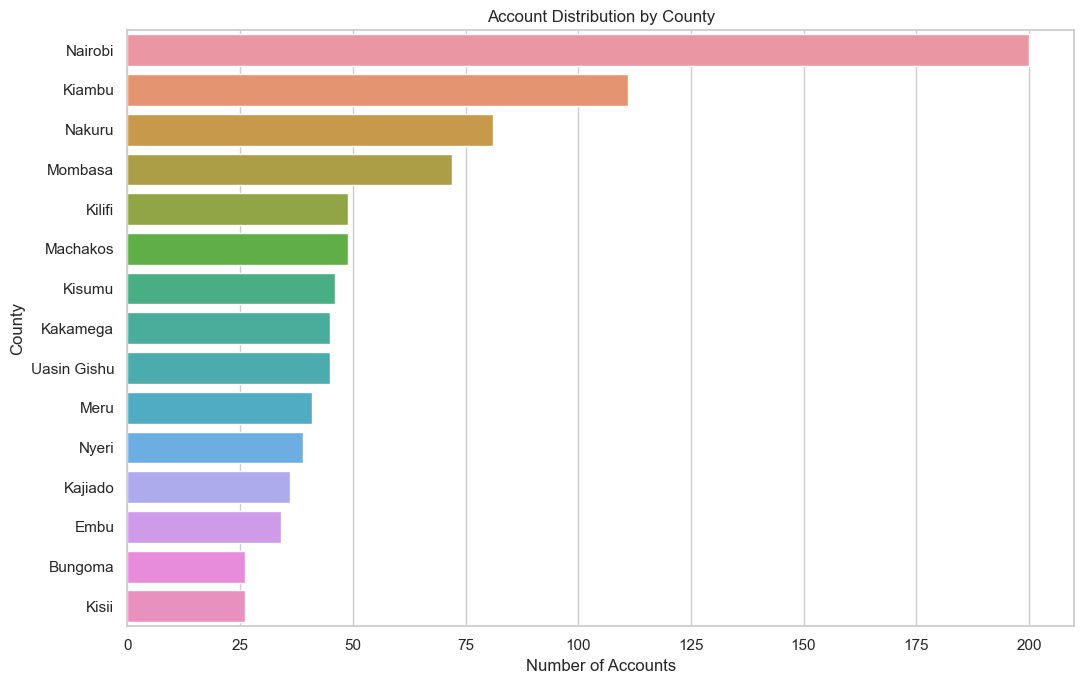

In [65]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=account_county_summary,
    x='Total_Accounts',
    y='county'
)

plt.title('Account Distribution by County')
plt.xlabel('Number of Accounts')
plt.ylabel('County')

plt.tight_layout()
plt.show()

**Chart Interpretation:**

- Nairobi has the highest account representation, followed by Kiambu and Nakuru.
- Mombasa ranks fourth with 72 accounts.
- Bungoma and Kisii have the lowest account counts.
- Account distribution broadly follows the customer distribution pattern.

**Business Interpretation:**

The bank has a higher concentration of accounts in Nairobi, Kiambu and Nakuru. These regions represent important areas of existing banking activity. Counties with lower account representation can be investigated for potential customer acquisition and account growth opportunities.

### 11.3 Transaction Activity by County

In [66]:
transaction_county_data = (
    transactions
    .merge(
        accounts[['account_id', 'county_id']],
        on='account_id',
        how='left'
    )
    .merge(
        counties[['county_id', 'county']],
        on='county_id',
        how='left'
    )
)

transaction_county_data.head()

,transaction_id,account_id,txn_date,txn_type,channel,purpose,amount_kes,balance_kes,txn_month,county_id,county
0,1000001,2087,2021-01-01,CREDIT,Branch,Opening deposit,33418,33418,2021-01,5,Nakuru
1,1000002,2840,2021-01-01,CREDIT,Branch,Opening deposit,70427,70427,2021-01,3,Kajiado
2,1000003,2847,2021-01-01,CREDIT,Branch,Opening deposit,91161,91161,2021-01,1,Nairobi
3,1000004,2170,2021-01-02,CREDIT,Branch,Opening deposit,78303,78303,2021-01,1,Nairobi
4,1000005,2841,2021-01-02,CREDIT,Branch,Opening deposit,59206,59206,2021-01,5,Nakuru


#### County-wise Transaction Analysis

In [67]:
transaction_county_summary = (
    transaction_county_data
    .groupby('county')
    .agg(
        Total_Transactions=('transaction_id', 'count'),
        Total_Transaction_Value=('amount_kes', 'sum'),
        Average_Transaction_Value=('amount_kes', 'mean')
    )
    .reset_index()
)

transaction_county_summary['Transaction_Percentage'] = (
    transaction_county_summary['Total_Transactions']
    / transaction_county_data['transaction_id'].count() * 100
).round(2)

transaction_county_summary['Average_Transaction_Value'] = (
    transaction_county_summary['Average_Transaction_Value']
).round(2)

transaction_county_summary = transaction_county_summary.sort_values(
    'Total_Transactions',
    ascending=False
)

transaction_county_summary

,county,Total_Transactions,Total_Transaction_Value,Average_Transaction_Value,Transaction_Percentage
11,Nairobi,23481,1471061173,62649.00,22.82
4,Kiambu,12954,755422172,58315.75,12.59
12,Nakuru,8605,389367498,45248.98,8.36
10,Mombasa,8022,314620172,39219.67,7.80
8,Machakos,5609,245015299,43682.53,5.45
14,Uasin Gishu,5447,220179041,40422.07,5.29
5,Kilifi,5382,222990416,41432.63,5.23
3,Kakamega,5190,189059481,36427.65,5.04
7,Kisumu,4965,178395598,35930.63,4.83
9,Meru,4623,177893261,38480.05,4.49


**Key Observations:**

- Nairobi has the highest transaction count with 23,481 transactions (22.82%).
- Kiambu ranks second with 12,954 transactions (12.59%).
- Nairobi has the highest total transaction value of approximately KES 1.47 billion.
- Kiambu has the second-highest total transaction value of approximately KES 755.42 million.
- Nairobi also has the highest average transaction value of KES 62,649.00.
- Kajiado has a relatively high average transaction value of KES 49,554.64.
- Kisii has the lowest transaction count and total transaction value.
- Transaction activity and average transaction values vary across counties.

**Business Interpretation:**

Nairobi and Kiambu account for a substantial share of the bank's transaction activity and monetary transaction value. However, transaction frequency and average transaction value show different patterns across counties.

The bank can use these findings to understand regional banking activity and investigate opportunities to improve customer engagement and services.

**Data Limitation:**

Transactions are analysed at account level using the county associated with each account. Joint-account transactions cannot be attributed to individual customers. Total transaction value represents gross recorded transaction amounts, not bank revenue or profit.

#### Transaction Count by County Chart

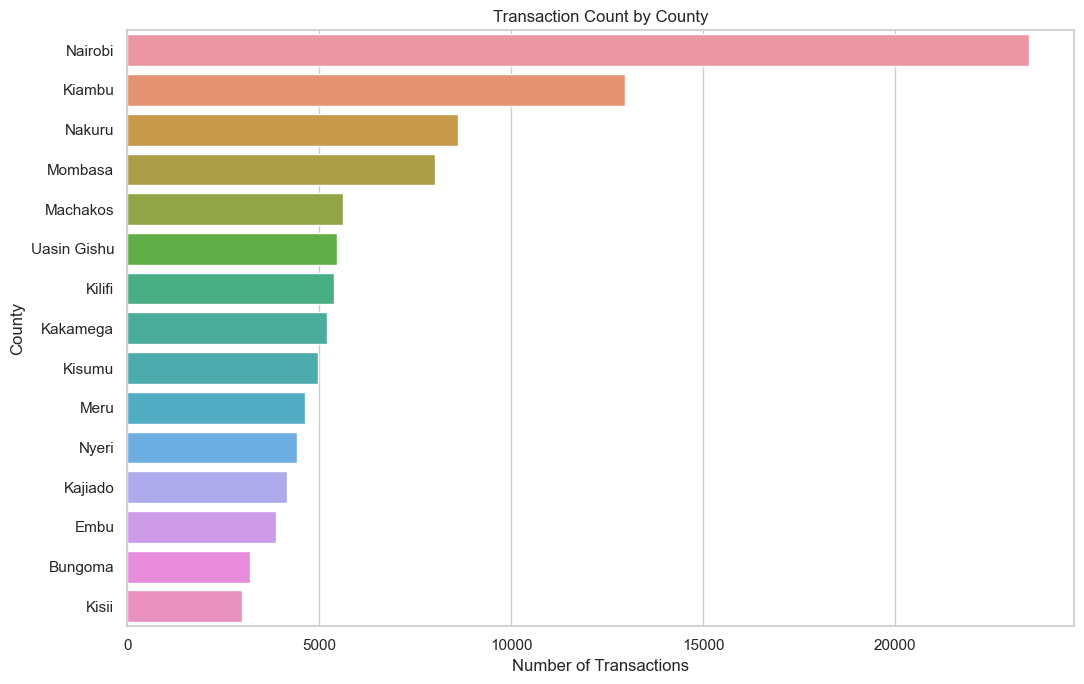

In [68]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=transaction_county_summary,
    x='Total_Transactions',
    y='county'
)

plt.title('Transaction Count by County')
plt.xlabel('Number of Transactions')
plt.ylabel('County')

plt.tight_layout()
plt.show()

**Chart Interpretation:**

- Nairobi has the highest transaction activity, followed by Kiambu and Nakuru.
- Mombasa also shows considerable transaction activity.
- Kisii has the lowest transaction count.
- Transaction activity is concentrated more heavily in Nairobi and Kiambu.

**Business Interpretation:**

Nairobi and Kiambu account for a substantial share of recorded transaction activity. These counties represent important areas of banking activity. The bank can investigate regional customer engagement and service requirements to understand these differences.

#### Total Transaction Value by County

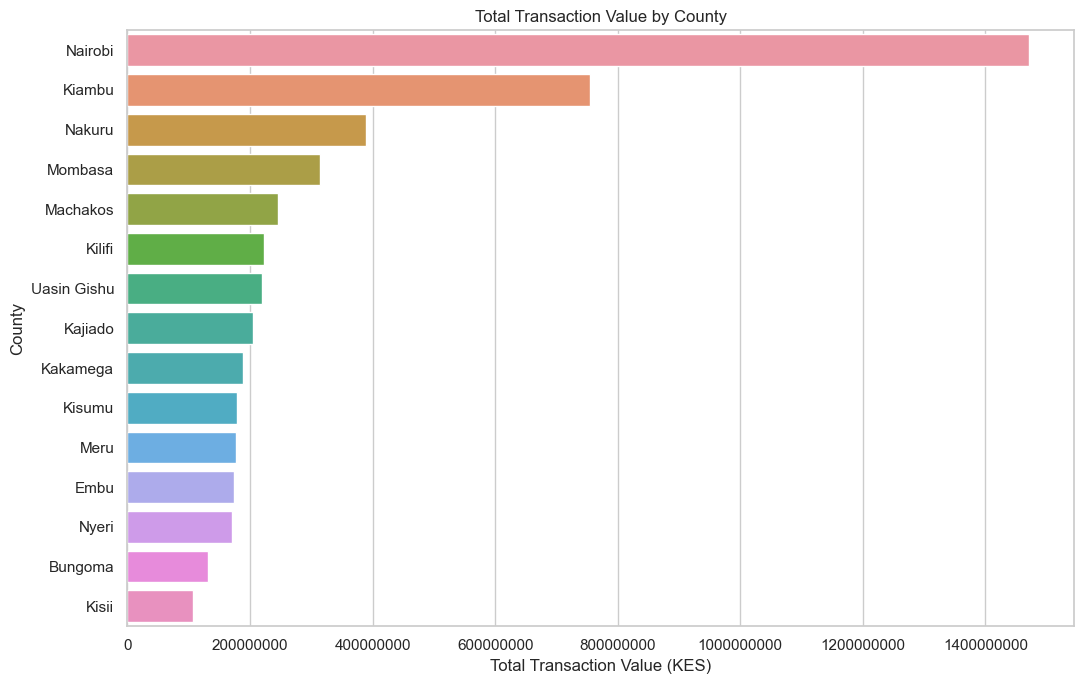

In [69]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=transaction_county_summary.sort_values(
        'Total_Transaction_Value',
        ascending=False
    ),
    x='Total_Transaction_Value',
    y='county'
)

plt.title('Total Transaction Value by County')
plt.xlabel('Total Transaction Value (KES)')
plt.ylabel('County')

plt.ticklabel_format(
    style='plain',
    axis='x'
)

plt.tight_layout()
plt.show()

**Chart Interpretation:**

- Nairobi has the highest total transaction value of approximately KES 1.47 billion.
- Kiambu ranks second with approximately KES 755.42 million.
- Nakuru and Mombasa also contribute substantial transaction values.
- Kisii has the lowest total transaction value.
- Transaction value is concentrated more heavily in Nairobi and Kiambu.

**Business Interpretation:**

Nairobi and Kiambu account for a substantial share of the recorded transaction value. These counties represent important areas of banking activity. The bank can investigate regional transaction patterns to understand differences in customer activity and service requirements.

#### Average Transaction Value by County

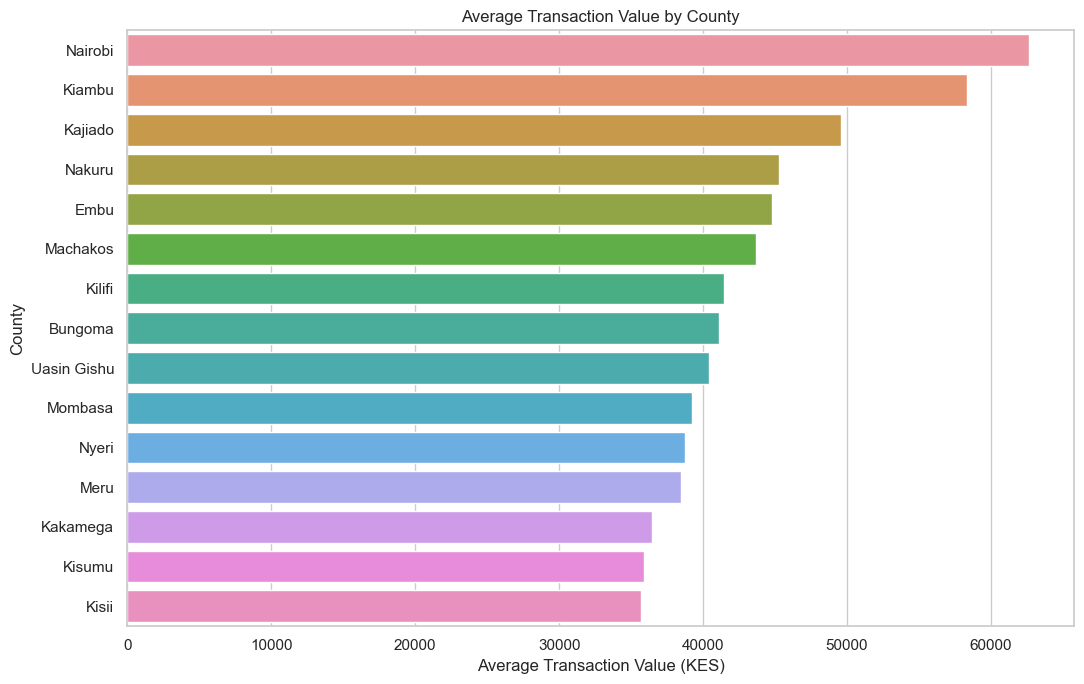

In [70]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=transaction_county_summary.sort_values(
        'Average_Transaction_Value',
        ascending=False
    ),
    x='Average_Transaction_Value',
    y='county'
)

plt.title('Average Transaction Value by County')
plt.xlabel('Average Transaction Value (KES)')
plt.ylabel('County')

plt.ticklabel_format(
    style='plain',
    axis='x'
)

plt.tight_layout()
plt.show()

**Chart Interpretation:**

- Nairobi has the highest average transaction value at KES 62,649.00.
- Kiambu ranks second with KES 58,315.75.
- Kajiado ranks third with KES 49,554.64.
- Kisii has the lowest average transaction value at KES 35,699.34.
- Average transaction values vary across counties.

**Business Interpretation:**

Nairobi and Kiambu show comparatively higher average transaction values. Kajiado also demonstrates relatively high average transaction activity despite having a lower transaction count than several other counties.

These differences highlight the importance of analysing transaction frequency and average transaction value separately.

### 11.4 Loan Distribution by County

In [72]:
loan_county_data = (
    loans
    .merge(
        accounts[['account_id', 'county_id']],
        on='account_id',
        how='left'
    )
    .merge(
        counties[['county_id', 'county']],
        on='county_id',
        how='left'
    )
)

loan_county_data.head()

,loan_id,account_id,loan_date,amount_kes,duration_months,monthly_payment_kes,status,county_id,county
0,7001,2001,2023-11-08,445000,12,39955,Repaid,6,Uasin Gishu
1,7002,2005,2023-11-14,238000,24,11427,Current,5,Nakuru
2,7003,2006,2024-06-08,462000,12,41482,Current,7,Machakos
3,7004,2008,2023-12-03,354000,12,31785,Repaid,6,Uasin Gishu
4,7005,2009,2023-07-21,333000,12,29899,Defaulted,2,Kiambu


#### County-wise Loan Analysis

In [73]:
loan_county_summary = (
    loan_county_data
    .groupby('county')
    .agg(
        Loan_Count=('loan_id', 'nunique'),
        Total_Loan_Amount=('amount_kes', 'sum'),
        Average_Loan_Amount=('amount_kes', 'mean')
    )
    .reset_index()
)

loan_county_summary['Loan_Percentage'] = (
    loan_county_summary['Loan_Count']
    / loan_county_data['loan_id'].nunique() * 100
).round(2)

loan_county_summary['Average_Loan_Amount'] = (
    loan_county_summary['Average_Loan_Amount']
).round(2)

loan_county_summary = loan_county_summary.sort_values(
    'Loan_Count',
    ascending=False
)

loan_county_summary

,county,Loan_Count,Total_Loan_Amount,Average_Loan_Amount,Loan_Percentage
11,Nairobi,62,37783000,609403.23,20.95
4,Kiambu,43,21279000,494860.47,14.53
10,Mombasa,23,7399000,321695.65,7.77
12,Nakuru,23,9474000,411913.04,7.77
8,Machakos,20,6473000,323650.00,6.76
3,Kakamega,18,5771000,320611.11,6.08
7,Kisumu,18,5688000,316000.00,6.08
5,Kilifi,14,3785000,270357.14,4.73
1,Embu,13,4839000,372230.77,4.39
14,Uasin Gishu,13,4965000,381923.08,4.39


**Key Observations:**

- Nairobi has the highest number of loans, with 62 loans (20.95%).
- Kiambu ranks second with 43 loans (14.53%).
- Mombasa and Nakuru have 23 loans each.
- Bungoma has the lowest number of loans, with 7 loans (2.36%).
- Nairobi records the highest total loan amount of KES 37.78 million.
- Nairobi also has the highest average loan amount of KES 609,403.23.
- Bungoma has the lowest average loan amount of KES 241,285.71.

**Business Interpretation:**

Nairobi and Kiambu represent important regions in the bank's loan portfolio, contributing the highest loan counts and total loan amounts.

However, loan distribution varies across counties. Comparing loan count, total loan amount and average loan amount separately helps the bank understand regional lending patterns.

#### Visualization: Loan Count by County

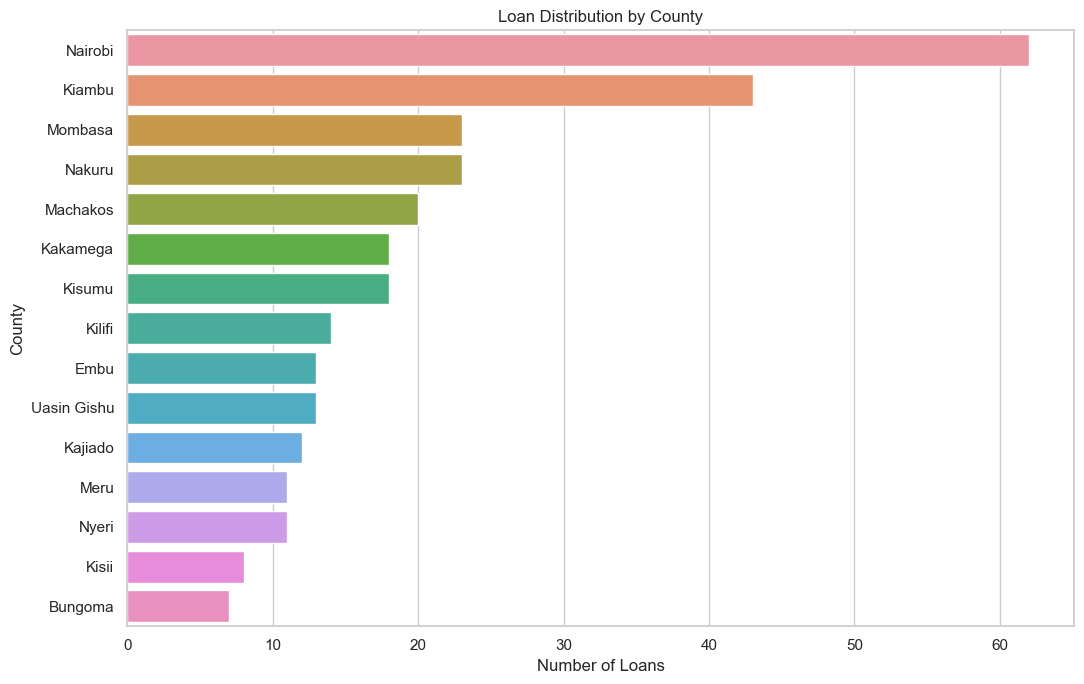

In [74]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=loan_county_summary.sort_values(
        'Loan_Count',
        ascending=False
    ),
    x='Loan_Count',
    y='county'
)

plt.title('Loan Distribution by County')
plt.xlabel('Number of Loans')
plt.ylabel('County')

plt.tight_layout()
plt.show()

**Chart Interpretation:**

- Nairobi has the highest loan count with 62 loans.
- Kiambu ranks second with 43 loans.
- Mombasa and Nakuru have 23 loans each.
- Bungoma has the lowest loan count with 7 loans.
- Loan distribution varies considerably across counties.

**Business Interpretation:**

Nairobi and Kiambu account for a substantial share of the bank's loan portfolio by loan count. These counties represent important lending markets in the observed dataset.

The bank can further investigate regional lending patterns to understand differences in loan demand and product adoption.

### Total Loan Amount by County

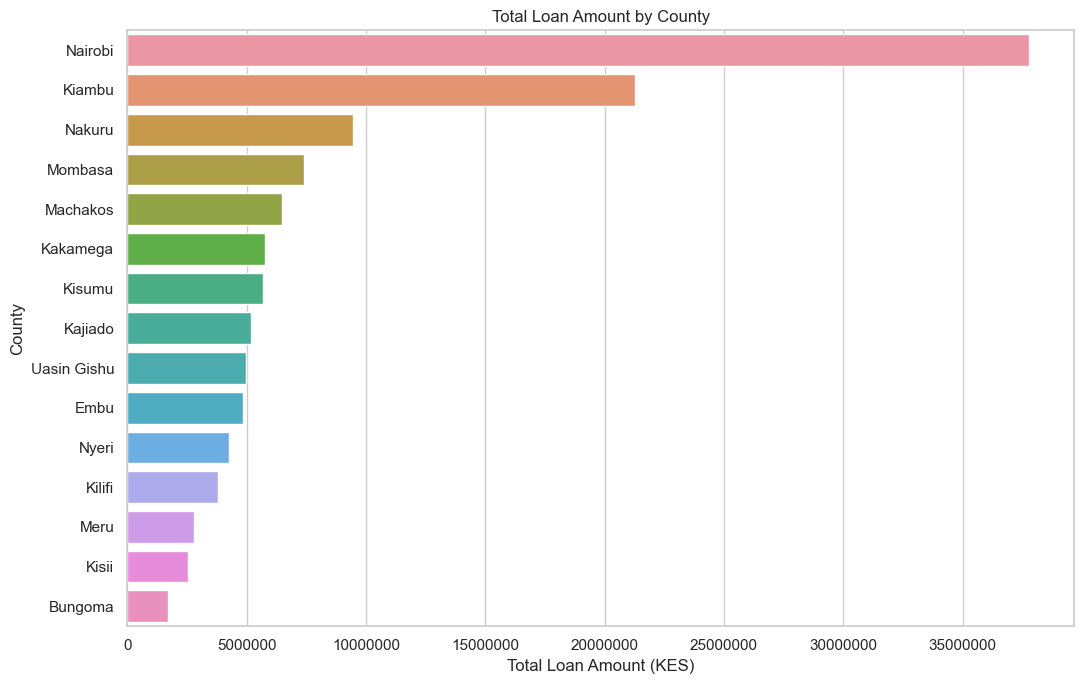

In [75]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=loan_county_summary.sort_values(
        'Total_Loan_Amount',
        ascending=False
    ),
    x='Total_Loan_Amount',
    y='county'
)

plt.title('Total Loan Amount by County')
plt.xlabel('Total Loan Amount (KES)')
plt.ylabel('County')

plt.ticklabel_format(
    style='plain',
    axis='x'
)

plt.tight_layout()
plt.show()

**Chart Interpretation:**

- Nairobi has the highest total loan amount of KES 37.78 million.
- Kiambu ranks second with KES 21.28 million.
- Nakuru records KES 9.47 million in total loan amount.
- Mombasa records KES 7.40 million.
- Bungoma has the lowest total loan amount of KES 1.69 million.

**Business Interpretation:**

Nairobi and Kiambu contribute the largest amounts to the observed loan portfolio. These counties also have the highest loan counts.

The bank can further investigate regional lending patterns to understand differences in loan demand and loan sizes.

### Average Loan Amount by County

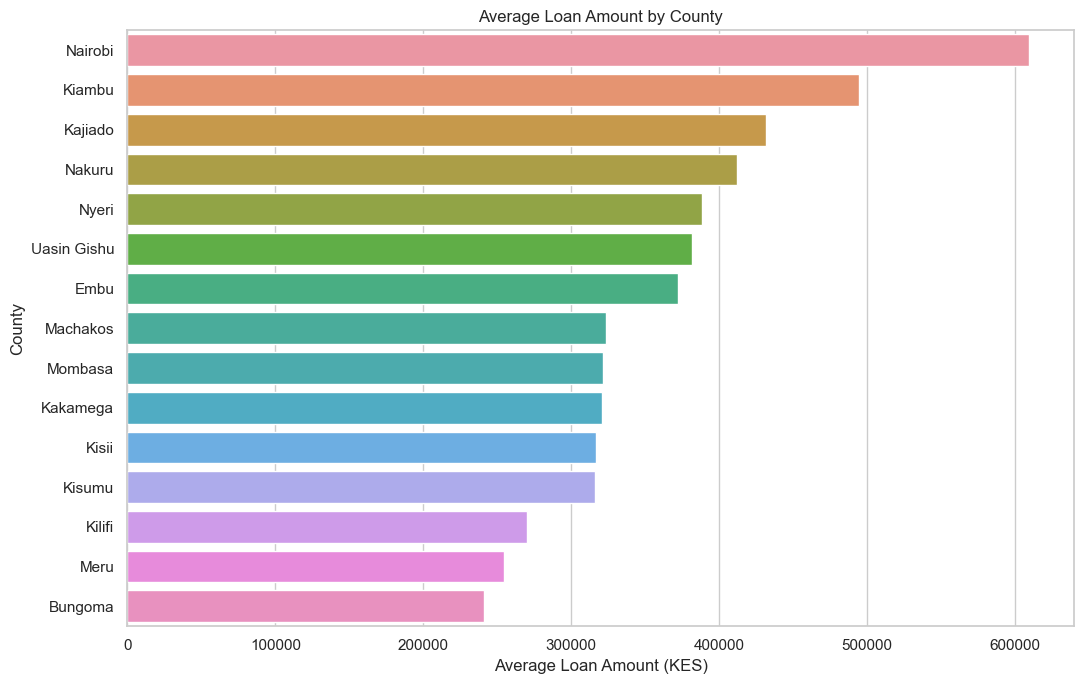

In [76]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=loan_county_summary.sort_values(
        'Average_Loan_Amount',
        ascending=False
    ),
    x='Average_Loan_Amount',
    y='county'
)

plt.title('Average Loan Amount by County')
plt.xlabel('Average Loan Amount (KES)')
plt.ylabel('County')

plt.ticklabel_format(
    style='plain',
    axis='x'
)

plt.tight_layout()
plt.show()

**Chart Interpretation:**

- Nairobi has the highest average loan amount at KES 609,403.23.
- Kiambu ranks second with KES 494,860.47.
- Kajiado ranks third with KES 431,916.67.
- Bungoma has the lowest average loan amount at KES 241,285.71.
- Average loan amounts vary considerably across counties.

**Business Interpretation:**

Nairobi and Kiambu have comparatively higher average loan amounts. Kajiado also shows a relatively high average loan amount despite having fewer loans.

These findings highlight differences in regional loan distribution and average loan sizes. Loan count and average loan amount should therefore be considered separately when evaluating regional lending patterns.

### Regional Analysis Conclusion

The regional analysis examined customer distribution, account distribution, card adoption, transaction behaviour and loan distribution across 15 counties.

**Key Findings:**

1. Nairobi has the highest customer base, with 226 customers (21.86%), followed by Kiambu with 126 customers (12.19%).

2. Nairobi also has the highest number of accounts, with 200 accounts (22.22%).

3. Card adoption varies across counties. Kisii has the highest adoption rate at 30.77%, while Machakos has the lowest at 15.38%.

4. Nairobi records the highest transaction activity, with 23,481 transactions and a total transaction value of approximately KES 1.47 billion.

5. Nairobi has the highest average transaction value at KES 62,649.00, while Kisii has the lowest at KES 35,699.34.

6. Nairobi has the highest loan count, with 62 loans, followed by Kiambu with 43 loans.

7. Nairobi records the highest total loan amount of KES 37.78 million and the highest average loan amount of KES 609,403.23.

8. Bungoma has the lowest loan count, with 7 loans, and the lowest average loan amount of KES 241,285.71.

**Business Insights:**

- Nairobi and Kiambu represent important markets in terms of customer distribution, banking activity and loan participation.
- Counties with lower card adoption may present opportunities for further card adoption initiatives.
- Regional differences in transaction frequency and average transaction value highlight the importance of analysing both metrics separately.
- Differences in loan count and average loan amount can help the bank understand regional lending patterns.
- Regional comparisons should consider customer and account population differences rather than relying only on absolute totals.

**Limitations:**

- County-level analysis uses the county associated with the account for account-based activities.
- County-level average income represents regional average income, not individual customer income.
- Higher transaction values do not necessarily indicate higher bank revenue or profitability.
- Loan distribution does not establish loan repayment performance or creditworthiness.
- The dataset represents synthetic banking data and should not be interpreted as actual bank performance.

# 12. Customer Segmentation



**Objective:**

Segment customers based on their transaction frequency and total transaction value to understand different banking behaviour patterns.

**Segmentation Categories:**

1. High Frequency - High Value
2. High Frequency - Low Value
3. Low Frequency - High Value
4. Low Frequency - Low Value

**Business Relevance:**

Customer segmentation can help the bank identify different customer behaviour patterns and explore suitable opportunities for customer engagement, product promotion and service improvement.

**Data Limitation:**

Transaction records are linked to accounts rather than individual customers. Therefore, this analysis will be performed at the account level. Transactions from joint accounts cannot be accurately attributed to individual account holders.

### 12.1 Account-level transaction metrics

In [77]:
account_segmentation = (
    transactions
    .groupby('account_id')
    .agg(
        Transaction_Count=('transaction_id', 'count'),
        Total_Transaction_Value=('amount_kes', 'sum')
    )
    .reset_index()
)

account_segmentation.head()

,account_id,Transaction_Count,Total_Transaction_Value
0,2001,65,4506082
1,2002,115,18813371
2,2003,128,4127343
3,2004,182,15349055
4,2005,106,3310167


In [78]:
account_segmentation[
    ['Transaction_Count', 'Total_Transaction_Value']
].describe().round(2)

,Transaction_Count,Total_Transaction_Value
count,900.00,900.00
mean,114.31,5501684.90
std,43.07,4149745.23
min,18.00,540169.00
25%,85.00,2723159.50
50%,110.00,4412864.50
75%,141.25,7165942.00
max,286.00,32697882.00


In [79]:
account_segmentation[
    ['Transaction_Count', 'Total_Transaction_Value']
].median()

Transaction_Count              110.0
Total_Transaction_Value    4412864.5
dtype: float64

### 12.2 Create Customer Segments (Account Level)

In [80]:
account_segmentation['Frequency_Segment'] = np.where(
    account_segmentation['Transaction_Count'] >= 110,
    'High Frequency',
    'Low Frequency'
)

account_segmentation['Value_Segment'] = np.where(
    account_segmentation['Total_Transaction_Value'] >= 4412864.50,
    'High Value',
    'Low Value'
)

account_segmentation['Customer_Segment'] = (
    account_segmentation['Frequency_Segment']
    + ' - '
    + account_segmentation['Value_Segment']
)

account_segmentation.head()

,account_id,Transaction_Count,Total_Transaction_Value,Frequency_Segment,Value_Segment,Customer_Segment
0,2001,65,4506082,Low Frequency,High Value,Low Frequency - High Value
1,2002,115,18813371,High Frequency,High Value,High Frequency - High Value
2,2003,128,4127343,High Frequency,Low Value,High Frequency - Low Value
3,2004,182,15349055,High Frequency,High Value,High Frequency - High Value
4,2005,106,3310167,Low Frequency,Low Value,Low Frequency - Low Value


In [81]:
account_segmentation.rename(
    columns={'Customer_Segment': 'Account_Segment'},
    inplace=True
)

In [82]:
segment_summary = (
    account_segmentation
    .groupby('Account_Segment')
    .agg(
        Account_Count=('account_id', 'count')
    )
    .reset_index()
)

segment_summary['Percentage'] = (
    segment_summary['Account_Count']
    / len(account_segmentation) * 100
)

segment_summary

,Account_Segment,Account_Count,Percentage
0,High Frequency - High Value,282,31.333333
1,High Frequency - Low Value,175,19.444444
2,Low Frequency - High Value,168,18.666667
3,Low Frequency - Low Value,275,30.555556


#### Visualization

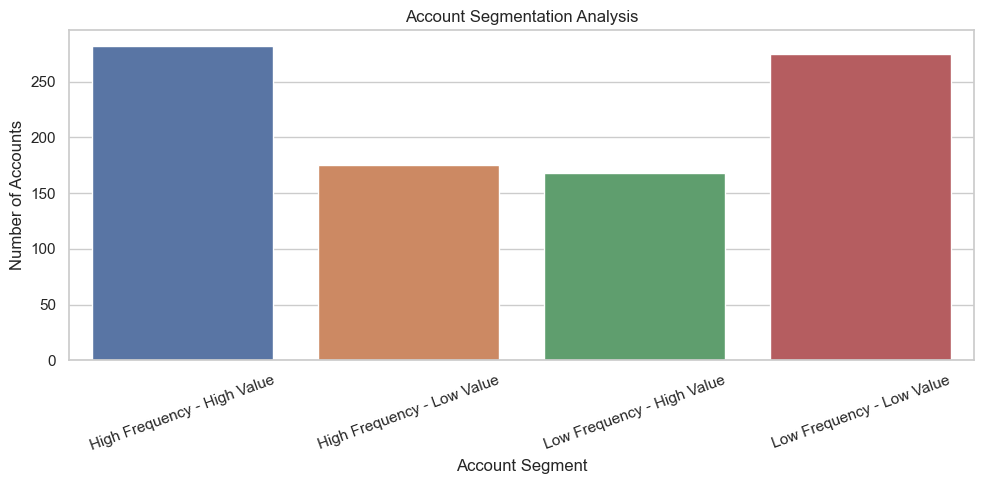

In [83]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=segment_summary,
    x='Account_Segment',
    y='Account_Count'
)

plt.title('Account Segmentation Analysis')
plt.xlabel('Account Segment')
plt.ylabel('Number of Accounts')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Business Interpretation

1. **High Frequency - High Value (31.33%)**: Largest segment. These accounts show both frequent transaction activity and high transaction value. They may be valuable accounts for relationship-building and retention.

2. **High Frequency - Low Value (19.44%)**: These accounts transact frequently but have lower cumulative transaction value. The bank could explore suitable product recommendations.

3. **Low Frequency - High Value (18.67%)**: These accounts have high transaction value despite lower frequency. The bank could explore ways to improve engagement.

4. **Low Frequency - Low Value (30.56%)**: These accounts show relatively low activity on both dimensions. The bank could investigate whether service awareness or engagement initiatives may help.

**Key Insight:** 31.33% of accounts fall into the High Frequency - High Value segment, while 30.56% fall into the Low Frequency - Low Value segment. This indicates different account engagement patterns that the bank can investigate.

**Note:** These are account-level segments based on median transaction frequency and total transaction value. They do not represent individual customer-level behaviour.

# Customer Segmentation Conclusion

The account segmentation analysis classified 900 accounts into four categories based on transaction frequency and total transaction value.

The High Frequency - High Value segment represents the largest share (31.33%), indicating accounts with relatively higher transaction activity and value. Meanwhile, 30.56% of accounts belong to the Low Frequency - Low Value segment, highlighting an opportunity to investigate engagement patterns.

The analysis provides a structured view of account-level transaction behaviour and can help the bank identify potential opportunities for customer engagement, retention and product recommendations.

**Limitation:** Transaction data is linked to accounts rather than individual customers. Therefore, the segmentation represents account-level behaviour and should not be interpreted as individual customer segmentation.

# 13. Key Business Insights

This section summarizes the key findings from customer demographics, account analysis, transaction behaviour, loan portfolio, card adoption, regional analysis and account segmentation.

The objective is to highlight important patterns, identify potential business opportunities and support data-driven banking decisions.

### 13.1 Customer Demographics Insights

- The customer base is primarily concentrated in the 26–45 age group, representing 58.80% of total customers.
- Customers aged 36–45 form the largest age group, accounting for 33.37% of the customer base.
- The gender distribution is relatively balanced, with males representing 52.42% and females 47.58%.

**Business Insights:**
- The bank has a strong customer base among individuals aged 26–45, providing an opportunity to explore relevant savings, investment and financial products.
- The relatively balanced gender distribution suggests that banking products and services can be designed to address the needs of both male and female customers.

### 13.2 Account Insights

- Current accounts represent the largest share of the account portfolio at 51.22%, followed by Savings accounts at 34.89% and Business accounts at 13.89%.
- Monthly statements are the most preferred statement frequency, selected by 73.11% of accounts.
- Weekly statements account for 17.00%, while Per Transaction statements account for 9.89%.

**Business Insights:**
- The high proportion of Current accounts indicates that the bank's account portfolio is primarily focused on current account usage.
- Savings accounts represent a significant portion of the portfolio, providing an opportunity to explore suitable savings and deposit products.
- Since most accounts use monthly statements, the bank should continue supporting monthly reporting while maintaining alternative statement preferences for customers.

### 13.3 Transaction Insights

- The dataset contains 102,880 transactions with a gross transaction value of approximately KES 4.95 billion.
- Debit transactions account for 58.68% of total transaction count, while Credit transactions represent 41.32%.
- Despite having fewer transactions, Credit transactions contribute a higher total value of approximately KES 2.82 billion, compared to KES 2.13 billion for Debit transactions.
- M-Pesa is the most frequently used transaction channel, accounting for 39.16% of all transactions.
- Bank transfers contribute approximately KES 1.22 billion in gross transaction value, while M-Pesa contributes approximately KES 2.22 billion.
- Monthly transaction activity generally increased over the analysed period from January 2021 to December 2024.

**Business Insights:**
- M-Pesa represents an important transaction channel, indicating significant customer usage of this payment method.
- The higher total value of Credit transactions, despite their lower count, indicates a higher average transaction value compared to Debit transactions.
- The bank can evaluate transaction channel usage to identify opportunities for improving digital banking services and customer convenience.
- The overall increase in monthly transaction activity suggests growing transaction engagement within the observed dataset.

**Limitation:** Gross transaction value represents the total value of recorded transactions. It should not be interpreted as bank revenue, profit or net liquidity.

### 13.4 Loan Portfolio Insights

- The dataset contains 296 loan records with an average loan amount of approximately KES 418,699.
- Current loans represent the largest share of the portfolio at 59.46%, followed by Repaid loans at 25%.
- In Arrears loans account for 9.12%, while Defaulted loans represent 6.42% of total loans.
- Combined, In Arrears and Defaulted loans account for 15.54% of the loan portfolio.
- Nairobi has the highest number of loans (62) and the highest total loan amount of approximately KES 37.78 million.

**Business Insights:**
- The majority of loans are currently classified as Current, indicating that most recorded loans are not marked as overdue or defaulted.
- The combined 15.54% share of In Arrears and Defaulted loans highlights the importance of monitoring loan portfolio risk.
- The bank can investigate the characteristics of loans in arrears and default to identify potential risk patterns.
- Nairobi represents the largest loan market in the observed dataset and may be an important region for further loan portfolio analysis.

**Limitation:** The dataset contains scheduled monthly payments but no actual repayment history. Therefore, repayment timeliness and borrower repayment behaviour cannot be assessed.

### 13.5 Card Adoption Insights

- Out of 1,034 customers, only 232 have an associated bank card, resulting in an overall card adoption rate of 22.44%.
- The remaining 802 customers (77.56%) do not have an associated card in the dataset.
- Classic cards dominate the card portfolio, representing 76.29% of all issued cards.
- Female customers have a slightly higher card adoption rate (23.78%) compared to male customers (21.22%).
- Kisii has the highest regional card adoption rate at 30.77%, while Machakos has the lowest at 15.38%.

**Business Insights:**
- The 77.56% of customers without an associated card represents a potential opportunity for the bank to explore card adoption.
- The strong presence of Classic cards indicates that they form the core of the existing card portfolio.
- The relatively small gender difference suggests that gender alone may not be a major factor in card adoption.
- Regional differences in card adoption can help the bank identify areas for further investigation and targeted awareness initiatives.

**Limitation:** The dataset records card issuance but does not contain activation or usage information. Therefore, card issuance should not be treated as proof of active card usage.

### 13.6 Regional Insights

- Nairobi has the highest customer concentration, representing 21.86% of the total customer base, followed by Kiambu at 12.19% and Nakuru at 9.96%.
- The top three counties account for 44.01% of total customers.
- Nairobi also has the highest number of accounts, representing 22.22% of all accounts.
- Nairobi records the highest transaction count (23,481) and gross transaction value (approximately KES 1.47 billion).
- Nairobi has the highest number of loans (62) and the highest total loan amount (approximately KES 37.78 million).
- Card adoption varies across counties, with Kisii recording the highest adoption rate (30.77%) and Machakos the lowest (15.38%).

**Business Insights:**
- Nairobi and Kiambu represent important banking markets due to their relatively high customer and account concentrations.
- Nairobi's leading transaction activity and loan portfolio make it an important region for further business analysis.
- Differences in card adoption across counties may help the bank identify regions where card awareness and adoption initiatives could be explored.
- Regional performance should be evaluated using transaction rates, averages and adoption percentages, rather than relying only on total counts and values.

**Limitation:** County-level findings describe the distribution of customers, accounts and banking activity in the available dataset. They do not necessarily represent the overall banking market or population of each county.

### 13.7 Account Segmentation Insights

- A total of 900 accounts were classified into four segments based on transaction frequency and total transaction value.
- High Frequency - High Value is the largest segment, representing 31.33% (282 accounts).
- Low Frequency - Low Value represents 30.56% (275 accounts), making it the second-largest segment.
- High Frequency - Low Value accounts represent 19.44% (175 accounts).
- Low Frequency - High Value accounts represent 18.67% (168 accounts).

**Business Insights:**
- The High Frequency - High Value segment represents an important group for relationship-building and retention initiatives.
- The High Frequency - Low Value segment may provide opportunities to explore suitable banking products and services.
- The Low Frequency - High Value segment may benefit from initiatives that encourage more frequent account engagement.
- The Low Frequency - Low Value segment can be investigated to understand low transaction activity and identify possible engagement opportunities.

**Limitation:** Segmentation is based on account-level transaction frequency and total transaction value using median thresholds. It does not represent individual customer behaviour or directly measure customer profitability.

### 13.8 Overall Business Insights Conclusion

The exploratory data analysis revealed several important patterns across the banking datasets.

The customer base is primarily concentrated in the 26–45 age group, while Current accounts represent the largest share of the account portfolio. Transaction analysis highlighted significant activity through M-Pesa and a higher gross transaction value from Credit transactions compared to Debit transactions.

The loan portfolio is largely classified as Current, although the combined share of loans in arrears and defaulted loans highlights the importance of continued risk monitoring. Card adoption remains relatively low, with only 22.44% of customers having an associated card in the dataset.

Regional analysis identified Nairobi as a major banking market in terms of customer concentration, account distribution, transaction activity and loan portfolio. Account segmentation further revealed distinct transaction behaviour patterns, with High Frequency - High Value and Low Frequency - Low Value being the two largest segments.

**Overall, these findings can help the bank:**

- Explore suitable banking products for different customer segments.
- Identify opportunities to improve card adoption.
- Monitor loan portfolio risk.
- Evaluate regional banking activity and opportunities.
- Improve customer engagement and account usage.
- Support data-driven business planning and decision-making.

**Final Note:** These findings are based on the available datasets and represent observed patterns rather than confirmed causal relationships. The analysis also has limitations, including the absence of individual-level transaction attribution, card activation data and actual loan repayment history.

# 14. EDA Conclusion

The Exploratory Data Analysis (EDA) provided an overall understanding of customer demographics, account distribution, transaction behaviour, loan portfolio, card adoption, regional performance and account-level transaction patterns.

The analysis was performed across seven datasets containing 106,391 records and 40 columns. It helped identify important trends, distributions, relationships and potential business opportunities within the available banking data.

### Key Findings

- **Customer Demographics:** The customer base is primarily concentrated in the 26–45 age group, representing 58.80% of total customers.
- **Account Analysis:** Current accounts represent the largest share of the account portfolio at 51.22%.
- **Transaction Analysis:** A total of 102,880 transactions were analysed, with a gross transaction value of approximately KES 4.95 billion. M-Pesa was the most frequently used transaction channel.
- **Loan Analysis:** The portfolio contains 296 loans, of which 15.54% are classified as In Arrears or Defaulted.
- **Card Adoption:** Overall card adoption is 22.44%, indicating potential opportunities to explore wider card adoption.
- **Regional Analysis:** Nairobi leads in customer concentration, account distribution, transaction activity and loan portfolio size.
- **Account Segmentation:** High Frequency - High Value accounts form the largest segment at 31.33%, followed by Low Frequency - Low Value accounts at 30.56%.

### Business Value

The findings provide useful insights that can support banking decisions related to customer engagement, product recommendations, card adoption, loan risk monitoring and regional business opportunities.

The analysis also establishes a foundation for further investigation using SQL and Power BI, where business metrics can be explored through structured queries and interactive dashboards.

### Limitations

- Transaction records are linked to accounts rather than individual customers.
- Card activation and usage information is unavailable.
- Actual loan repayment history is not available.
- County-level income represents regional averages rather than individual customer income.
- The dataset represents a limited set of banking records and should not be treated as actual industry-wide performance.

### Final Conclusion

This EDA project transformed raw banking datasets into meaningful analytical insights. It helped develop a better understanding of customer profiles, banking products, transaction patterns, loan portfolio characteristics and regional differences.

The completed analysis will serve as the foundation for the next stages of the project: SQL-based business analysis and Power BI dashboard development.